# Results

216 OASIS-1 patients with complete clinical data and all five MRI image types (no imputation), k = 4 clusters
for every configuration. Configurations are compared with the Pairwise Separability Index (PSI) on Age, MMSE,
nWBV, eTIV, Education, SES, CDR (|Cliff's δ|) and sex (Total Variation Distance); the one with the highest PSI is
selected.

Figures and tables come from notebooks 01–07 and are saved in `results/`.

1. Changes from the previous analysis
2. Implementation
3. Configurations
4. Number of clusters
5. Pairwise Separability Index
6. Clusters of every configuration
7. Cluster profiles of every configuration
8. Selected configuration
9. Stability
10. Robustness checks and secondary results
11. Comparison with the previous method

In [1]:
%run -i ../src/setup.ipynb
import json
from IPython.display import Image, Markdown
from sklearn.manifold import MDS
from scipy.spatial.distance import pdist, squareform

R = cfg.RESULTS_DIR
OUT = R / "09_results"
OUT.mkdir(parents=True, exist_ok=True)

def show_png(path, width=1000):
    display(Image(filename=str(path), width=width))

selection = json.loads((R / "02_compare_configurations" / "selection.json").read_text())
K = selection["k"]
labels = pd.read_csv(R / "02_compare_configurations" / "labels.csv")
psi = pd.read_csv(R / "02_compare_configurations" / "psi_table.csv", index_col=0)
df = load_analysis_data()
assert (labels["patient_id"] == df["patient_id"]).all()
ORDER = list(psi.loc["PSI (mean)"].sort_values(ascending=False).index)

## 1. Changes from the previous analysis

| Issue | Change |
|---|---|
| Configurations were judged by their agreement with CDR (ARI/NMI) | Configurations compared with the PSI; ARI/NMI against CDR kept as secondary results |
| Unscaled clinical variables dominated the distance | Clinical block with robust Mahalanobis distance; ASF removed (r = −0.99 with eTIV); images and clinical variables in separate blocks; images with Euclidean distance |
| Configurations used different samples and selection criteria | Same 216 patients for all configurations; no imputation; one selection rule fixed in advance |
| Software | robust-mixed-dist 0.1.31 and db-robust-clust 0.1.15; `SampleDistClustering` with `frac_sample_size = 1` for every k-medoids configuration; exact RelMS; G-Gower by blocks |
| Sex as an input | Sex only used to interpret the clusters: as its own binary block it weighed as much as all clinical variables together and every partition split into men and women |

Share of the previous clinical distance (unscaled Euclidean) due to each variable:

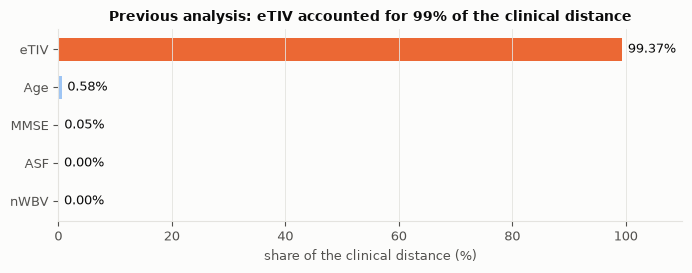

In [2]:
raw = pd.read_excel(cfg.CLINICAL_FILE).rename(columns={"ID": "patient_id"})
raw["patient_id"] = raw["patient_id"].str.replace(r"_MR\d+$", "", regex=True)
old = df[["patient_id", "Age", "MMSE", "eTIV", "nWBV"]].merge(
    raw[["patient_id", "ASF"]].drop_duplicates("patient_id"), on="patient_id")
v = old[["Age", "MMSE", "eTIV", "nWBV", "ASF"]].var()
share = (v / v.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(share.index, share.values, color=[CLUSTER_COLORS[1] if x > 50 else "#9ec5f4" for x in share.values], height=0.6)
for i, x in enumerate(share.values):
    ax.text(x + 1, i, f"{x:.2f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 110)
ax.set_xlabel("share of the clinical distance (%)")
ax.set_title("Previous analysis: eTIV accounted for 99% of the clinical distance")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(OUT / "etiv_share_previous.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Implementation

| Component | Source | Location |
|---|---|---|
| Pairwise Separability Index | `compute_config_pairwise_separability` by F. Scielzo-Ortiz, unchanged | `src/psi.ipynb` |
| Distances (G-Gower, RelMS, robust Mahalanobis) | robust-mixed-dist 0.1.31 | `src/clustering_utils.ipynb` |
| Clustering | `SampleDistClustering` (db-robust-clust 0.1.15), `frac_sample_size = 1`, PAM with `init = 'build'`, 100 iterations, `random_state = 123` | `src/clustering_utils.ipynb` |
| Exact RelMS | subclass of `SampleDistClustering` using `related_metric_scaling_dist_matrix` instead of `related_metric_scaling_dist_matrix_faster` | `src/clustering_utils.ipynb` |
| Robust covariance | `robust_method = 'trimmed'`, α = 0.05 | `src/config.ipynb` |
| Settings and configurations | one configuration object | `src/config.ipynb` |

## 3. Configurations

Image blocks: one per image type (110 PCA scores each), Euclidean distance. Clinical block: Age, MMSE, eTIV, nWBV,
Education and SES (Education and SES treated as ordinal), robust Mahalanobis distance. Each configuration differs
from its reference in one thing only.

In [3]:
rows = []
for name, c in cfg.CONFIGS.items():
    if c["algorithm"] == "kmeans":
        blocks, method = "standardised clinical (Euclidean)", "k-means"
    else:
        img = any(l in cfg.IMAGE_TYPES for l, _, _ in c["quant_blocks"])
        clin = [f"{l} (robust Mahalanobis)" for l, _, d in c["quant_blocks"] if l not in cfg.IMAGE_TYPES]
        blocks = " + ".join((["5 image blocks (Euclidean)"] if img else []) + clin)
        method = {"ggower": "G-Gower + PAM", "relms": "RelMS + PAM"}[c["metric"] or selection["m3_metric"]]
    rows.append({"ID": name, "feature space": c["feature_space"], "method": method, "blocks": blocks,
                 "tests": c["description"]})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows).set_index("ID")

,feature space,method,blocks,tests
ID,,,,
C1,Clinical,G-Gower + PAM,clinical (robust Mahalanobis),Clinical baseline
C1-b,Clinical,k-means,standardised clinical (Euclidean),Effect of the algorithm on the same features
C2,Clinical + CDR,G-Gower + PAM,clinical+CDR (robust Mahalanobis),Severity as part of the profile
I1,Images,RelMS + PAM,5 image blocks (Euclidean),Image-only structure
I2,Images,G-Gower + PAM,5 image blocks (Euclidean),RelMS vs. G-Gower on images
M1,Images + clinical,RelMS + PAM,5 image blocks (Euclidean) + clinical (robust Mahalanobis),Added value of images
M2,Images + clinical,G-Gower + PAM,5 image blocks (Euclidean) + clinical (robust Mahalanobis),"Same, with G-Gower"
M3,Images + clinical + CDR,G-Gower + PAM,5 image blocks (Euclidean) + clinical+CDR (robust Mahalanobis),Full profile including severity


## 4. Number of clusters

C1, M1 and I1 were fitted for k = 2 to 5, and k was chosen from the cluster profiles and medoids, with the PSI
as support. The other configurations were fitted directly at the chosen k.

| k | Clinical reference configuration C1 | Decision |
|---|---|---|
| 2 | impaired patients not separated (CDR PSI 0.08) | rejected |
| 3 | one impaired cluster, but one healthy cluster mixes ages 33 to 96 | rejected |
| **4** | young healthy; older healthy with atrophy; healthy with larger head; cognitively impaired | **selected** |
| 5 | splits the older healthy patients by education; PSI unchanged (0.444 vs 0.440) | rejected |

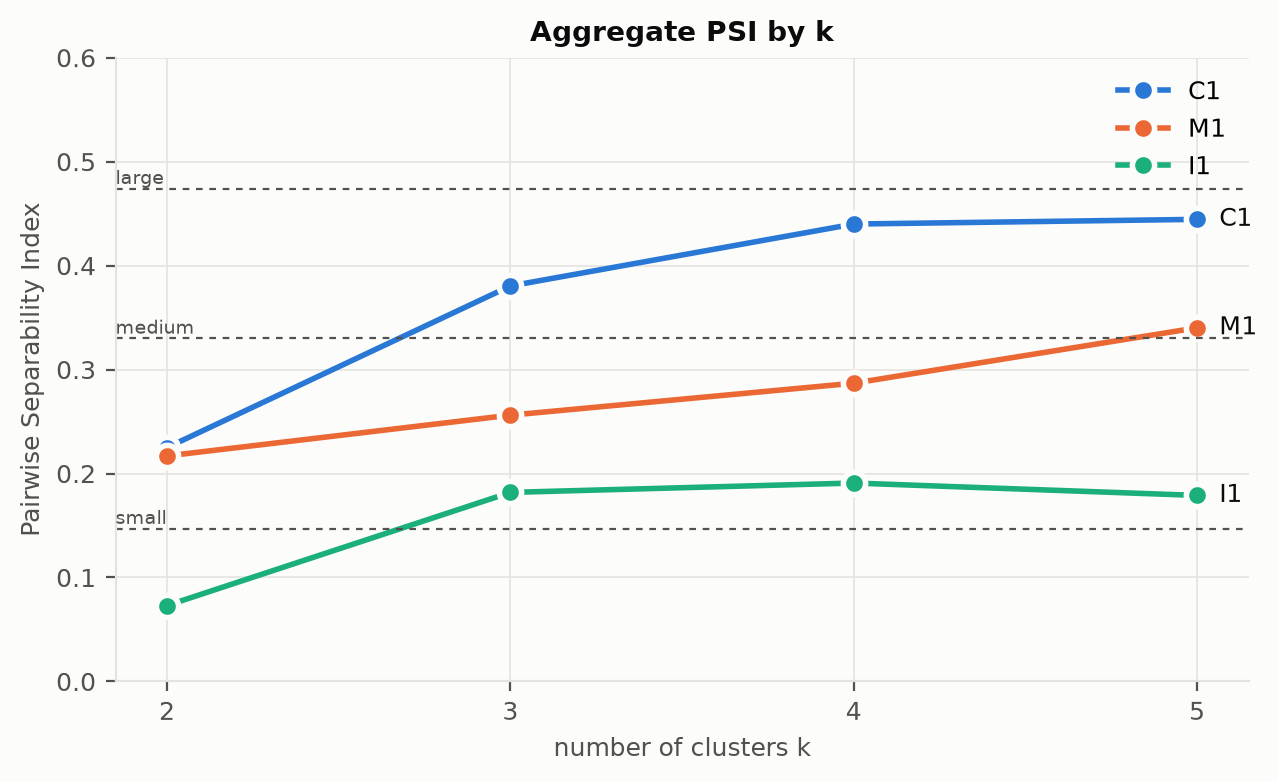

In [4]:
show_png(R / "01_choose_k" / "psi_by_k.png", 650)

## 5. Pairwise Separability Index (k = 4)

Mean |Cliff's δ| (ordered variables) or TVD (sex) over the 6 pairs of clusters. N = negligible (< 0.147),
S = small, M = medium (≥ 0.33), L = large (≥ 0.474). Highest value of each row in bold; configurations ordered by
aggregate PSI.

,C1-b,C1,C2,M3,M2,M1,I2,I1
Age,0.592 (L),0.656 (L),0.623 (L),0.338 (M),0.306 (S),0.370 (M),0.300 (S),0.263 (S)
MMSE,0.662 (L),0.484 (L),0.410 (M),0.296 (S),0.258 (S),0.244 (S),0.213 (S),0.137 (N)
nWBV,0.760 (L),0.704 (L),0.625 (L),0.501 (L),0.481 (L),0.418 (M),0.364 (M),0.318 (S)
eTIV,0.241 (S),0.254 (S),0.287 (S),0.511 (L),0.526 (L),0.265 (S),0.223 (S),0.296 (S)
Educ,0.683 (L),0.459 (M),0.356 (M),0.265 (S),0.320 (S),0.230 (S),0.131 (N),0.043 (N)
SES,0.606 (L),0.370 (M),0.337 (M),0.268 (S),0.296 (S),0.328 (S),0.126 (N),0.060 (N)
CDR,0.577 (L),0.434 (M),0.546 (L),0.245 (S),0.182 (S),0.240 (S),0.154 (S),0.134 (N)
sex,0.094 (N),0.160 (S),0.166 (S),0.334 (M),0.347 (M),0.200 (S),0.132 (N),0.275 (S)
PSI (mean),0.527 (L),0.440 (M),0.419 (M),0.345 (M),0.340 (M),0.287 (S),0.205 (S),0.191 (S)


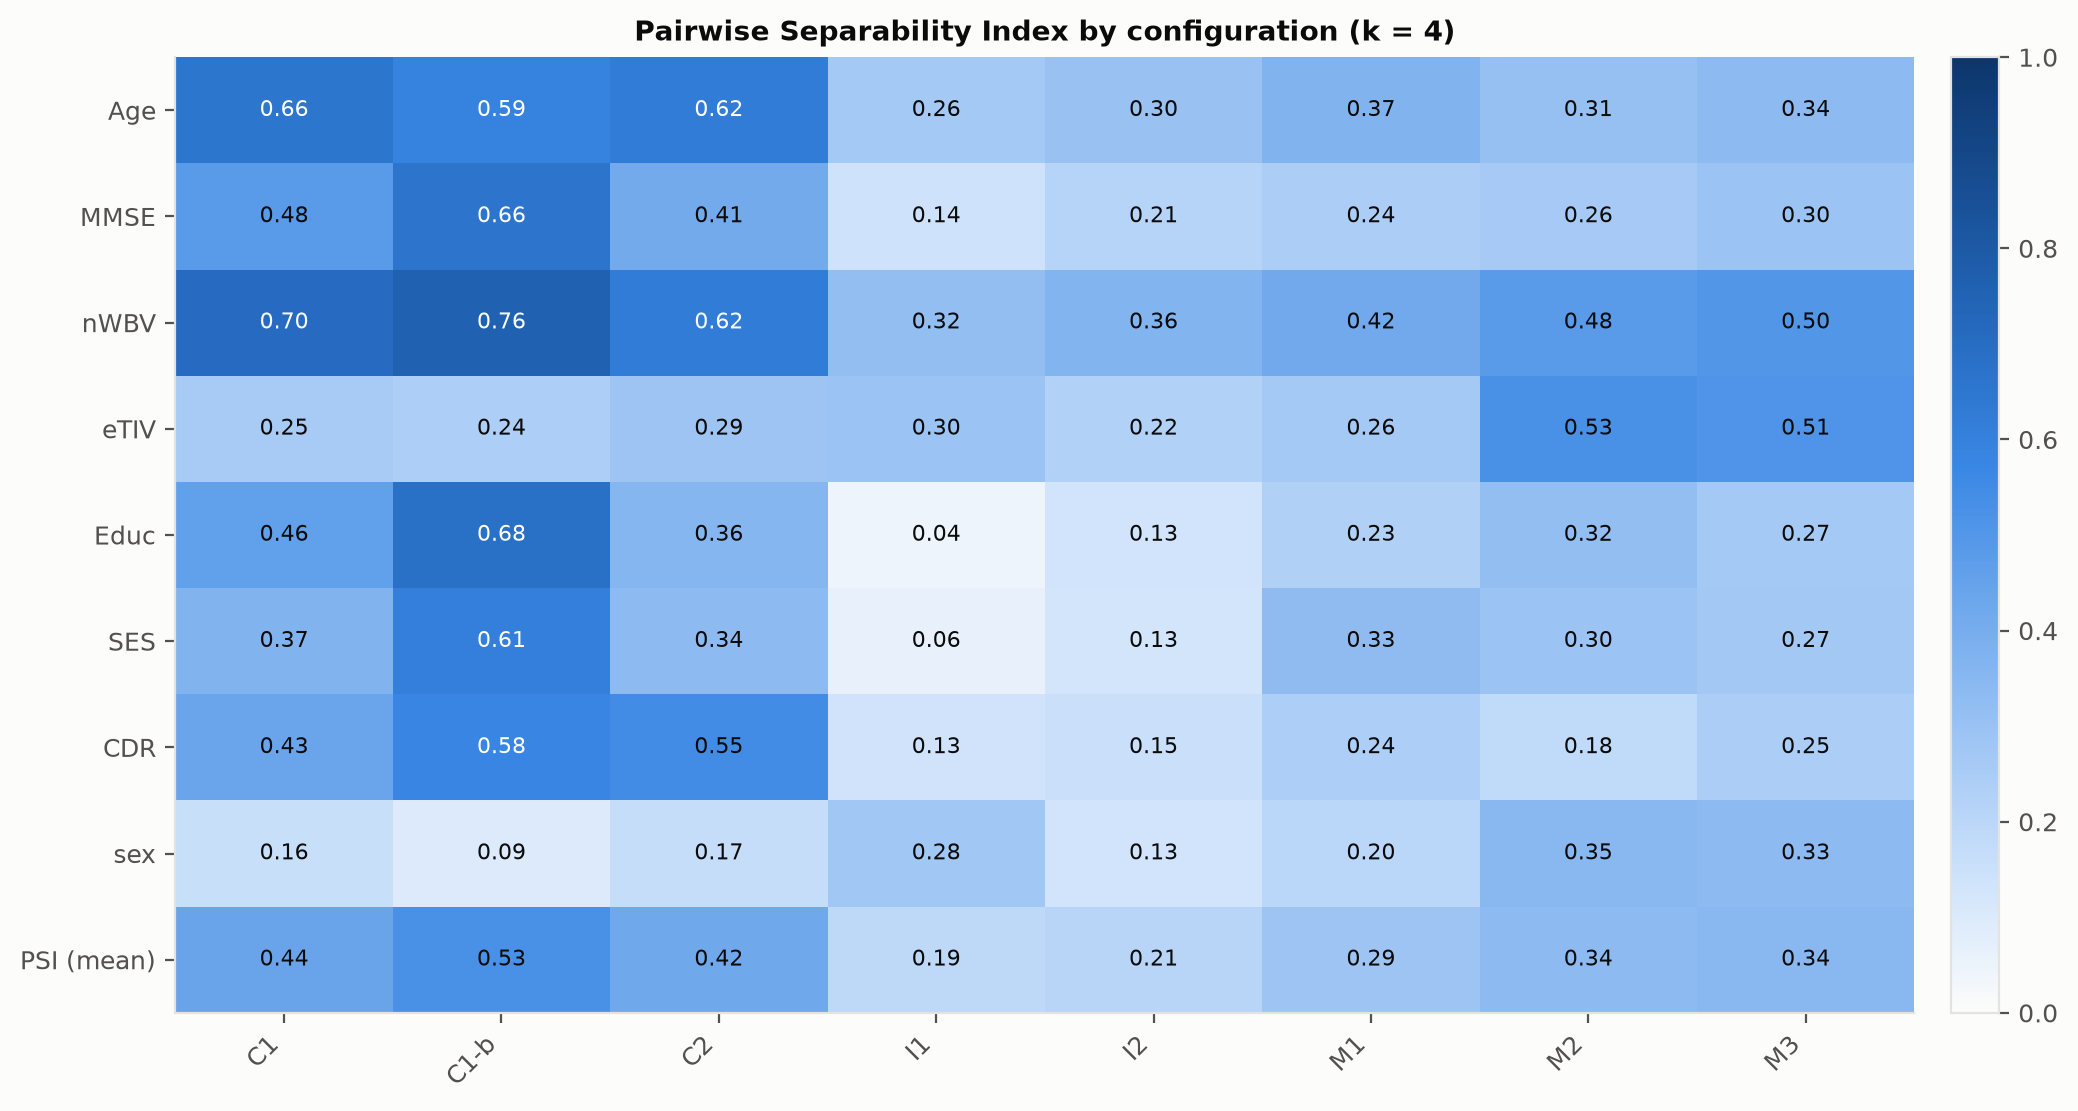

**Selected configuration: C1-b** (aggregate PSI 0.527). M3 uses G-Gower, the better of M1 and M2.

In [5]:
def bold_max(row):
    return ["font-weight: bold" if v == row.max() else "" for v in row]
table = psi[ORDER]
display(format_psi_table(table).style.apply(lambda r: bold_max(table.loc[r.name]), axis=1))
show_png(R / "02_compare_configurations" / "psi_table_heatmap.png", 800)
display(Markdown(f"**Selected configuration: {selection['selected']}** "
                 f"(aggregate PSI {selection['aggregate_psi'][selection['selected']]:.3f}). "
                 f"M3 uses {'G-Gower' if selection['m3_metric'] == 'ggower' else 'RelMS'}, the better of M1 and M2."))

## 6. Clusters of every configuration

Two-dimensional MDS of the distance each configuration was clustered on; each dot is a patient, coloured by
cluster. Clusters are numbered by decreasing mean MMSE, and configurations are ordered by aggregate PSI.

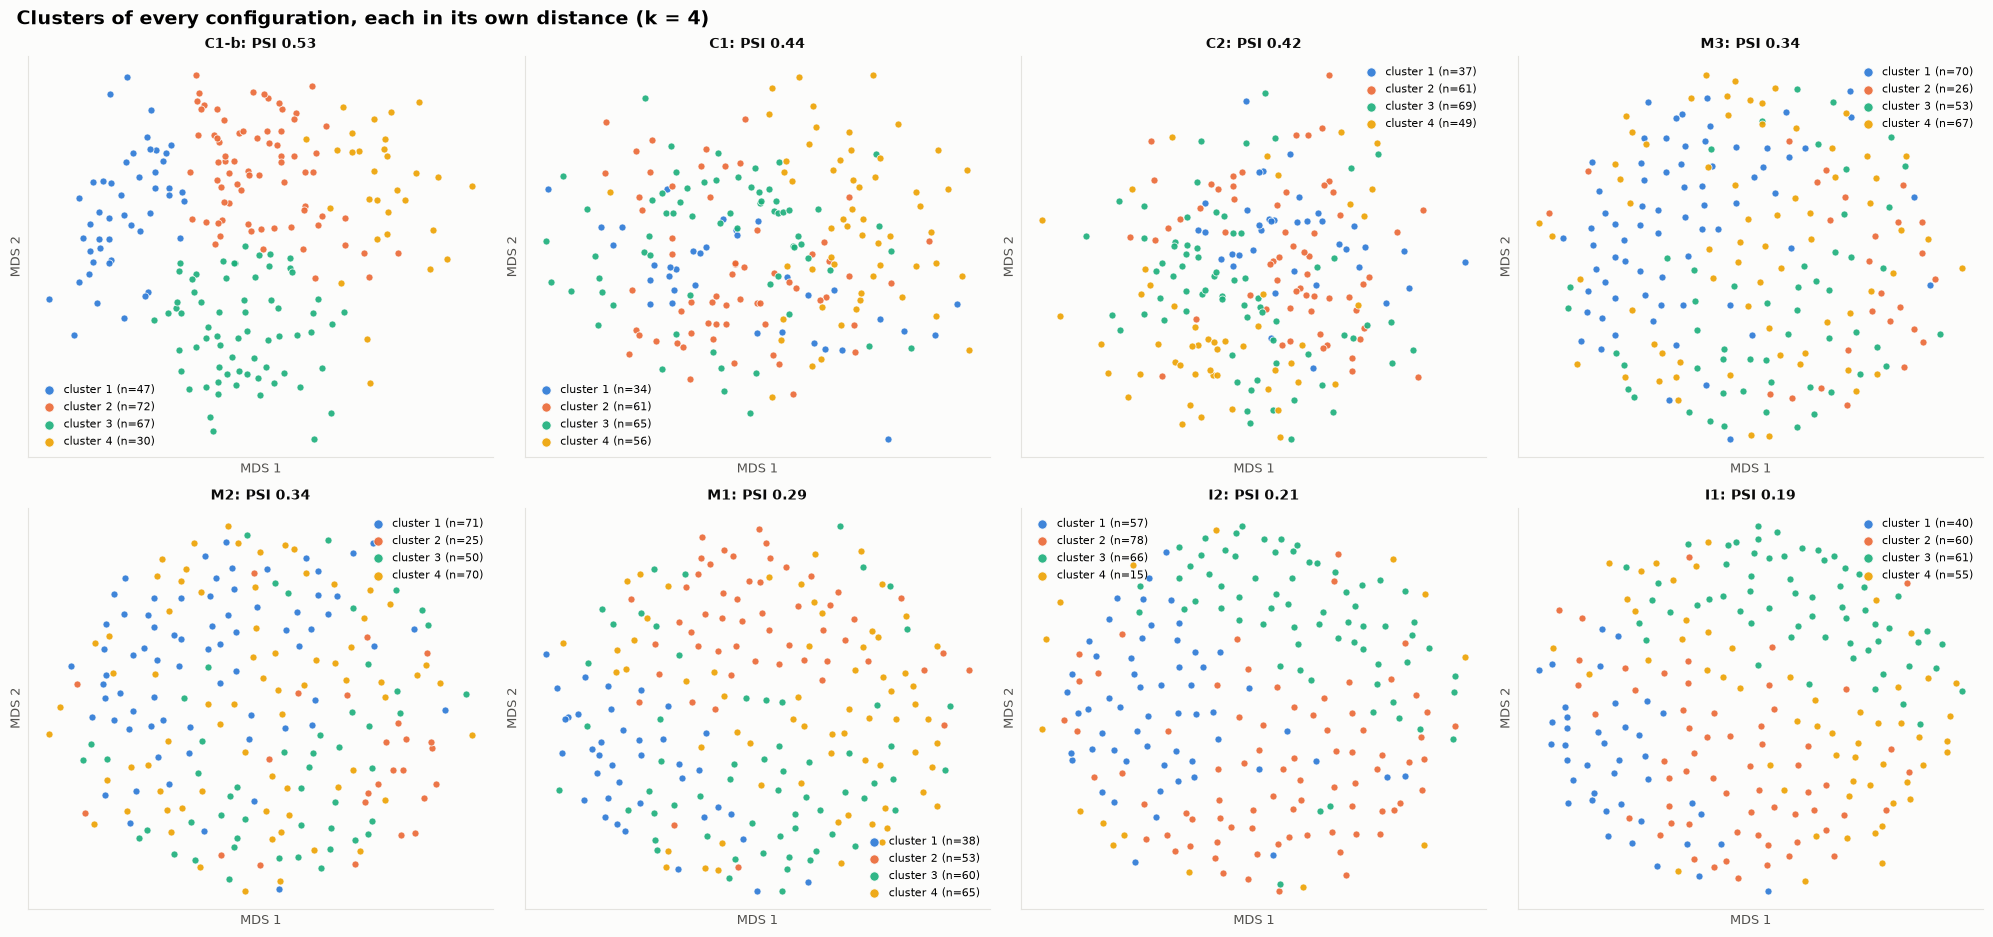

In [6]:
def config_distance(name):
    fit = fit_configuration(name, K, df, metric=selection["m3_metric"] if name == "M3" else None)
    return squareform(pdist(fit["X"])) if fit["D"] is None else fit["D"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
for ax, name in zip(axes.ravel(), ORDER):
    xy = MDS(n_components=2, metric="precomputed", init="random", n_init=4,
             random_state=42).fit_transform(config_distance(name))
    cluster_scatter(ax, xy[:, 0], xy[:, 1], labels[name].to_numpy(),
                    f"{name}: PSI {psi.loc['PSI (mean)', name]:.2f}", "MDS 1", "MDS 2")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Clusters of every configuration, each in its own distance (k = 4)", fontsize=14,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(OUT / "clusters_all_configurations_mds.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Cluster profiles of every configuration

Top: Age, MMSE, nWBV and eTIV by cluster (box = interquartile range, line = median, diamond = mean).
Bottom: share of each CDR, Education, SES and sex category within each cluster.

**C1-b**: Clinical, aggregate PSI 0.527

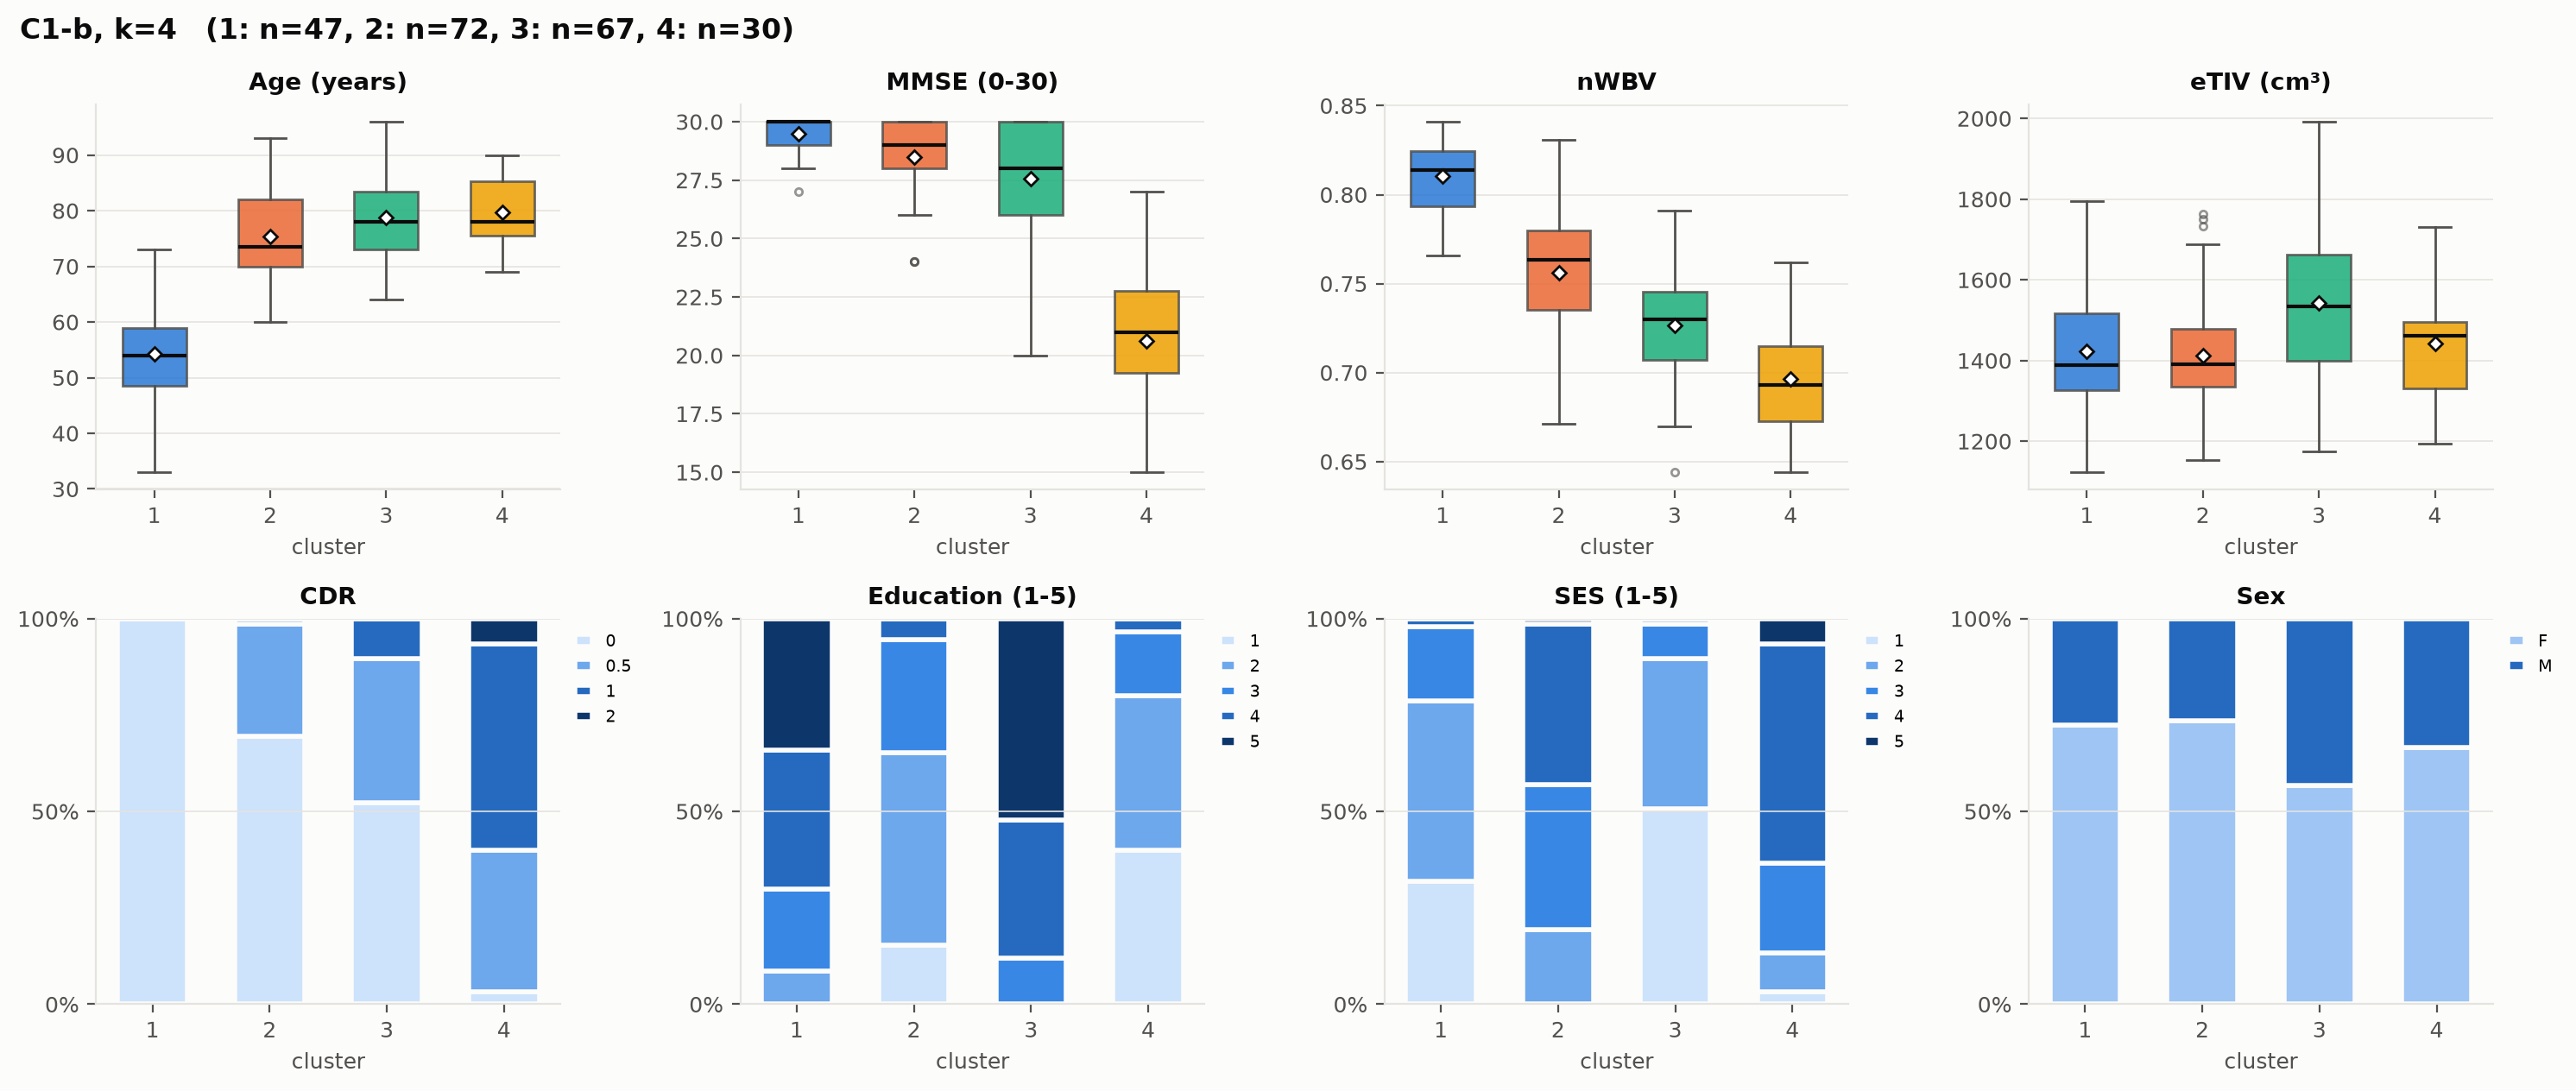

**C1**: Clinical, aggregate PSI 0.440

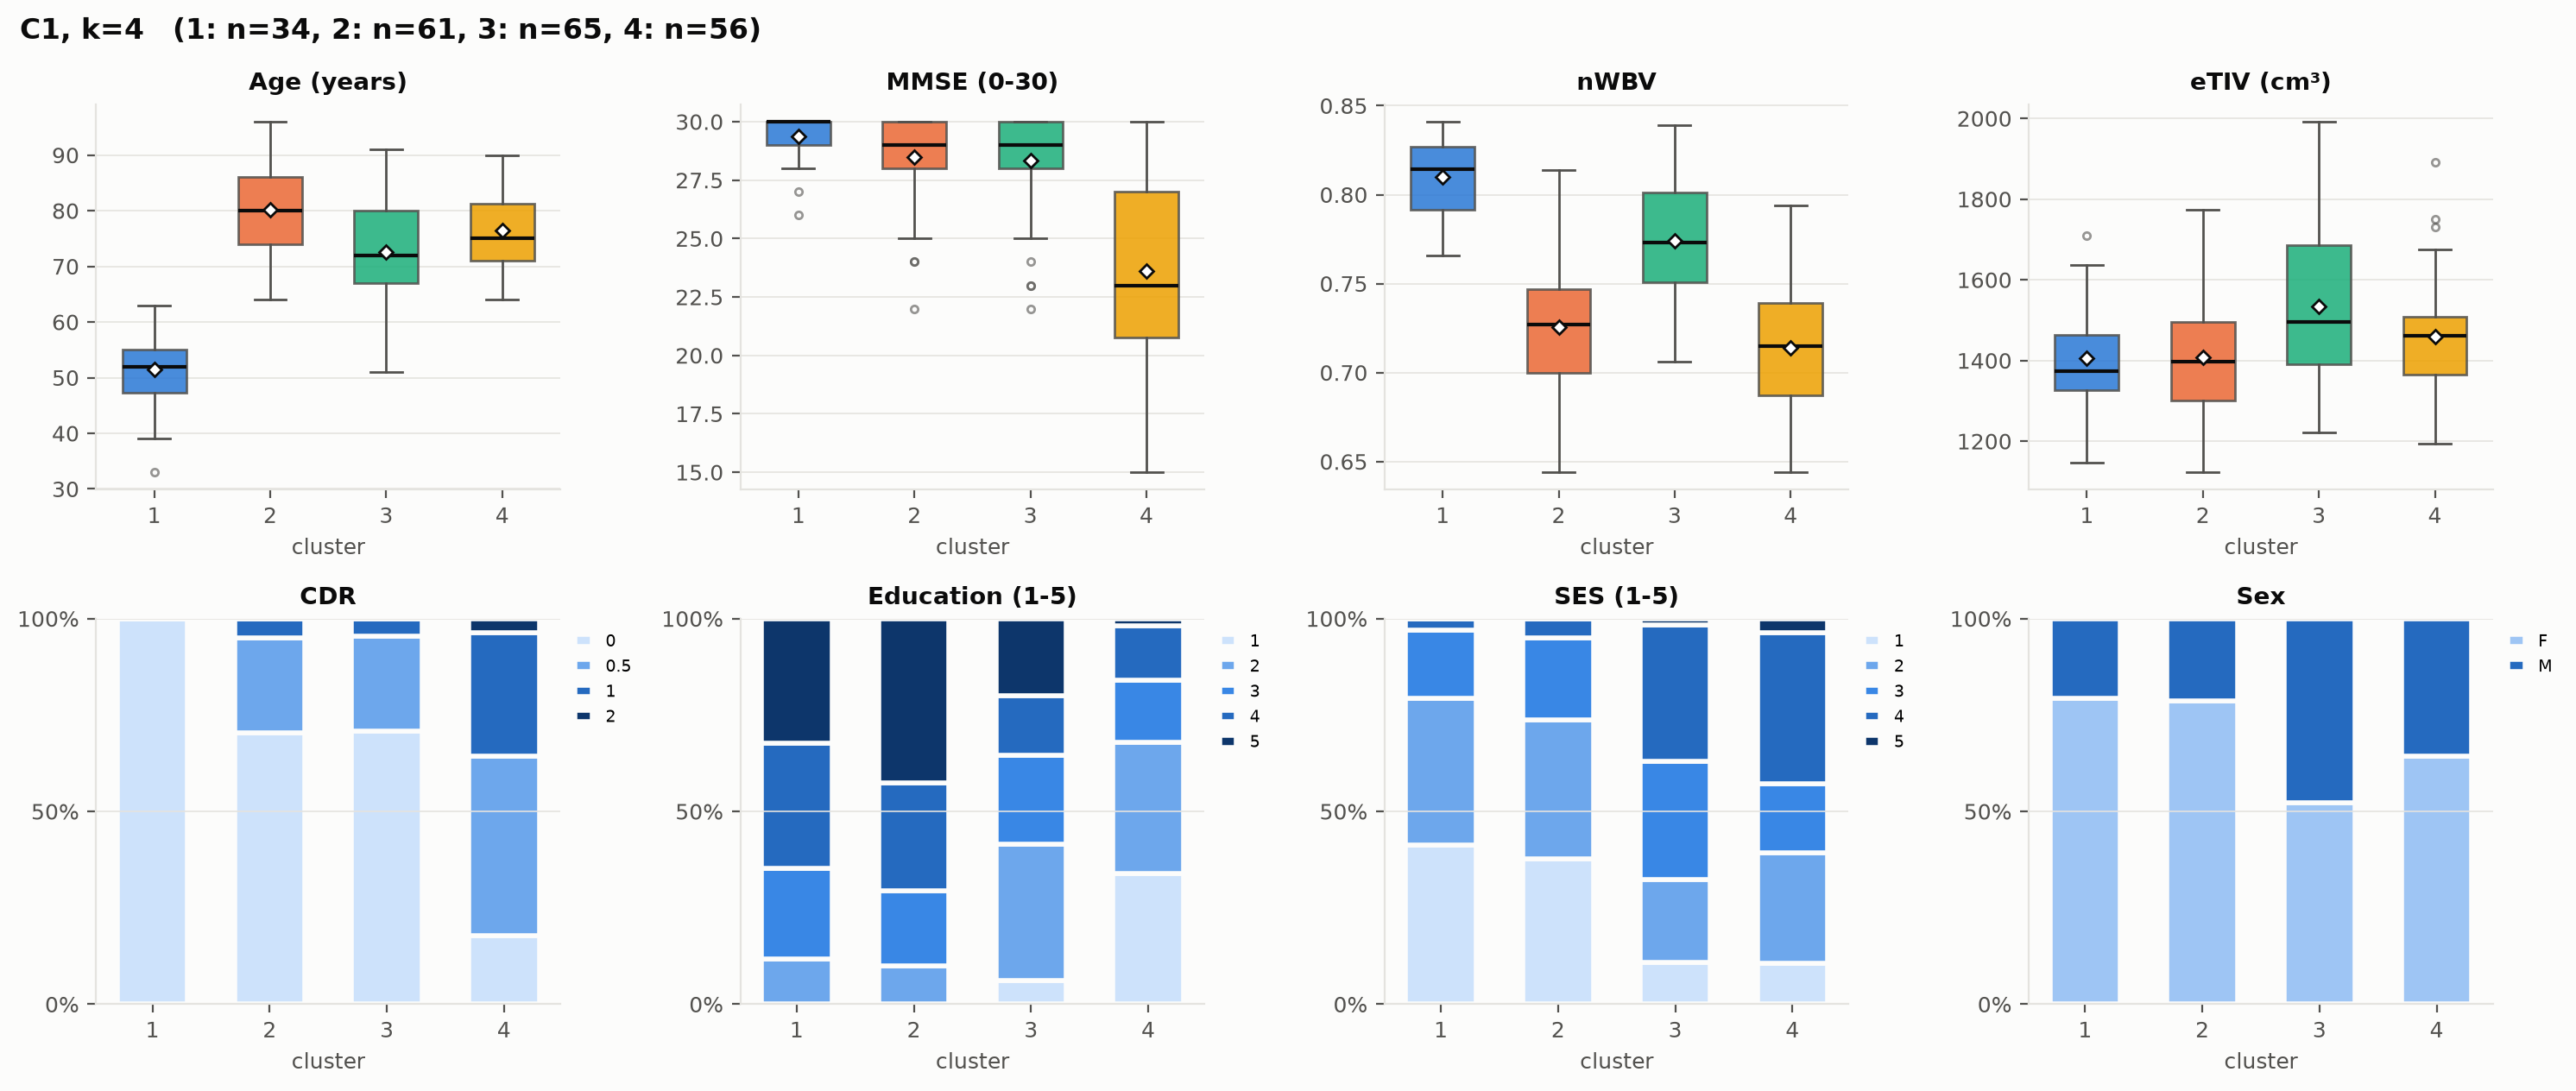

**C2**: Clinical + CDR, aggregate PSI 0.419

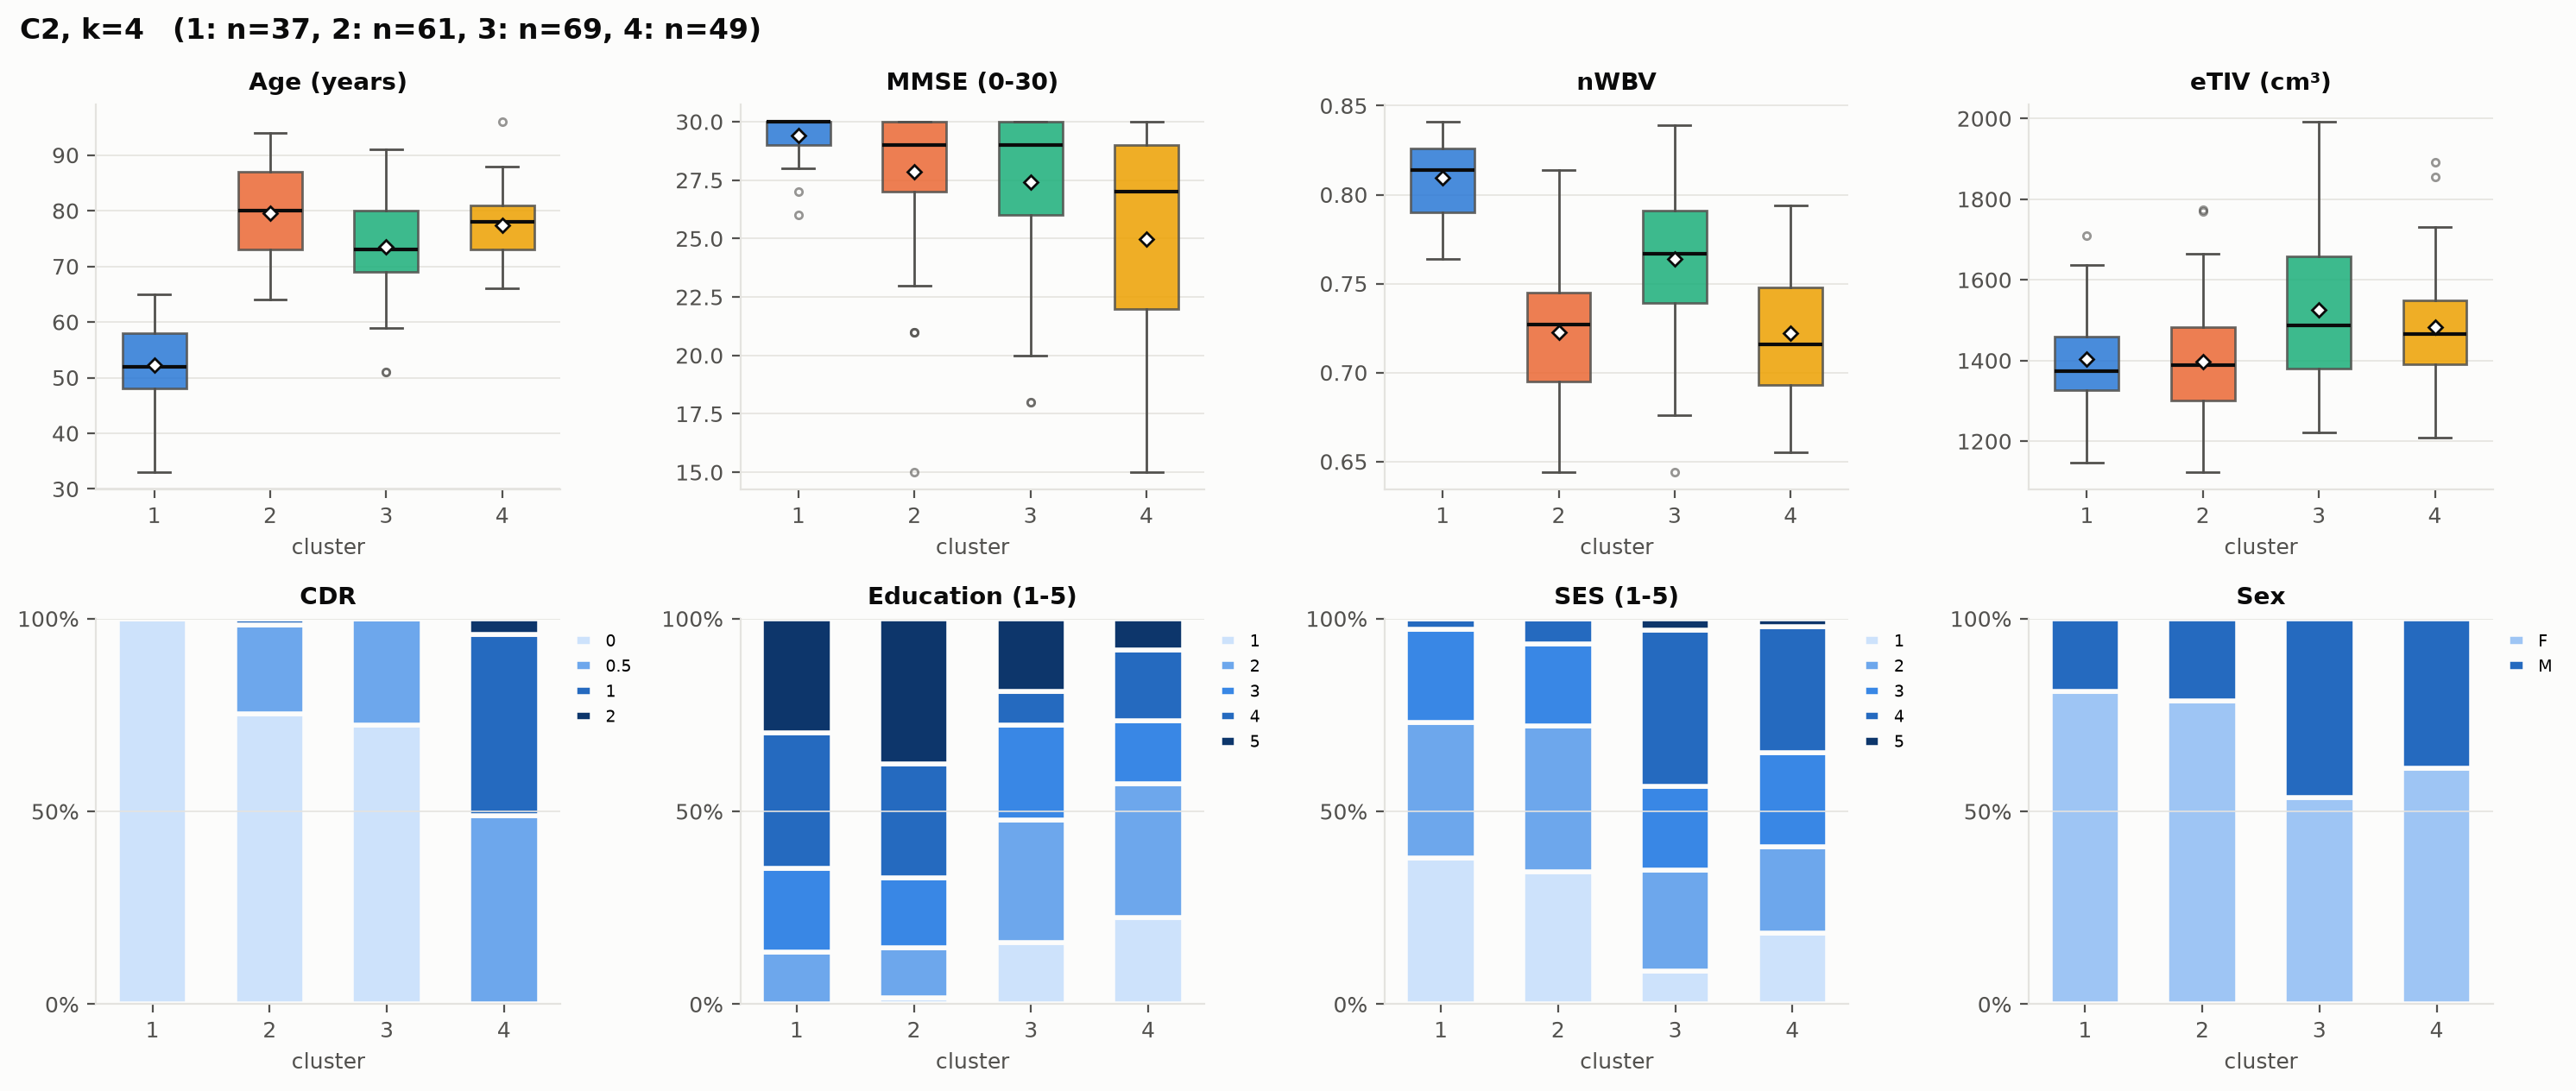

**M3**: Images + clinical + CDR, aggregate PSI 0.345

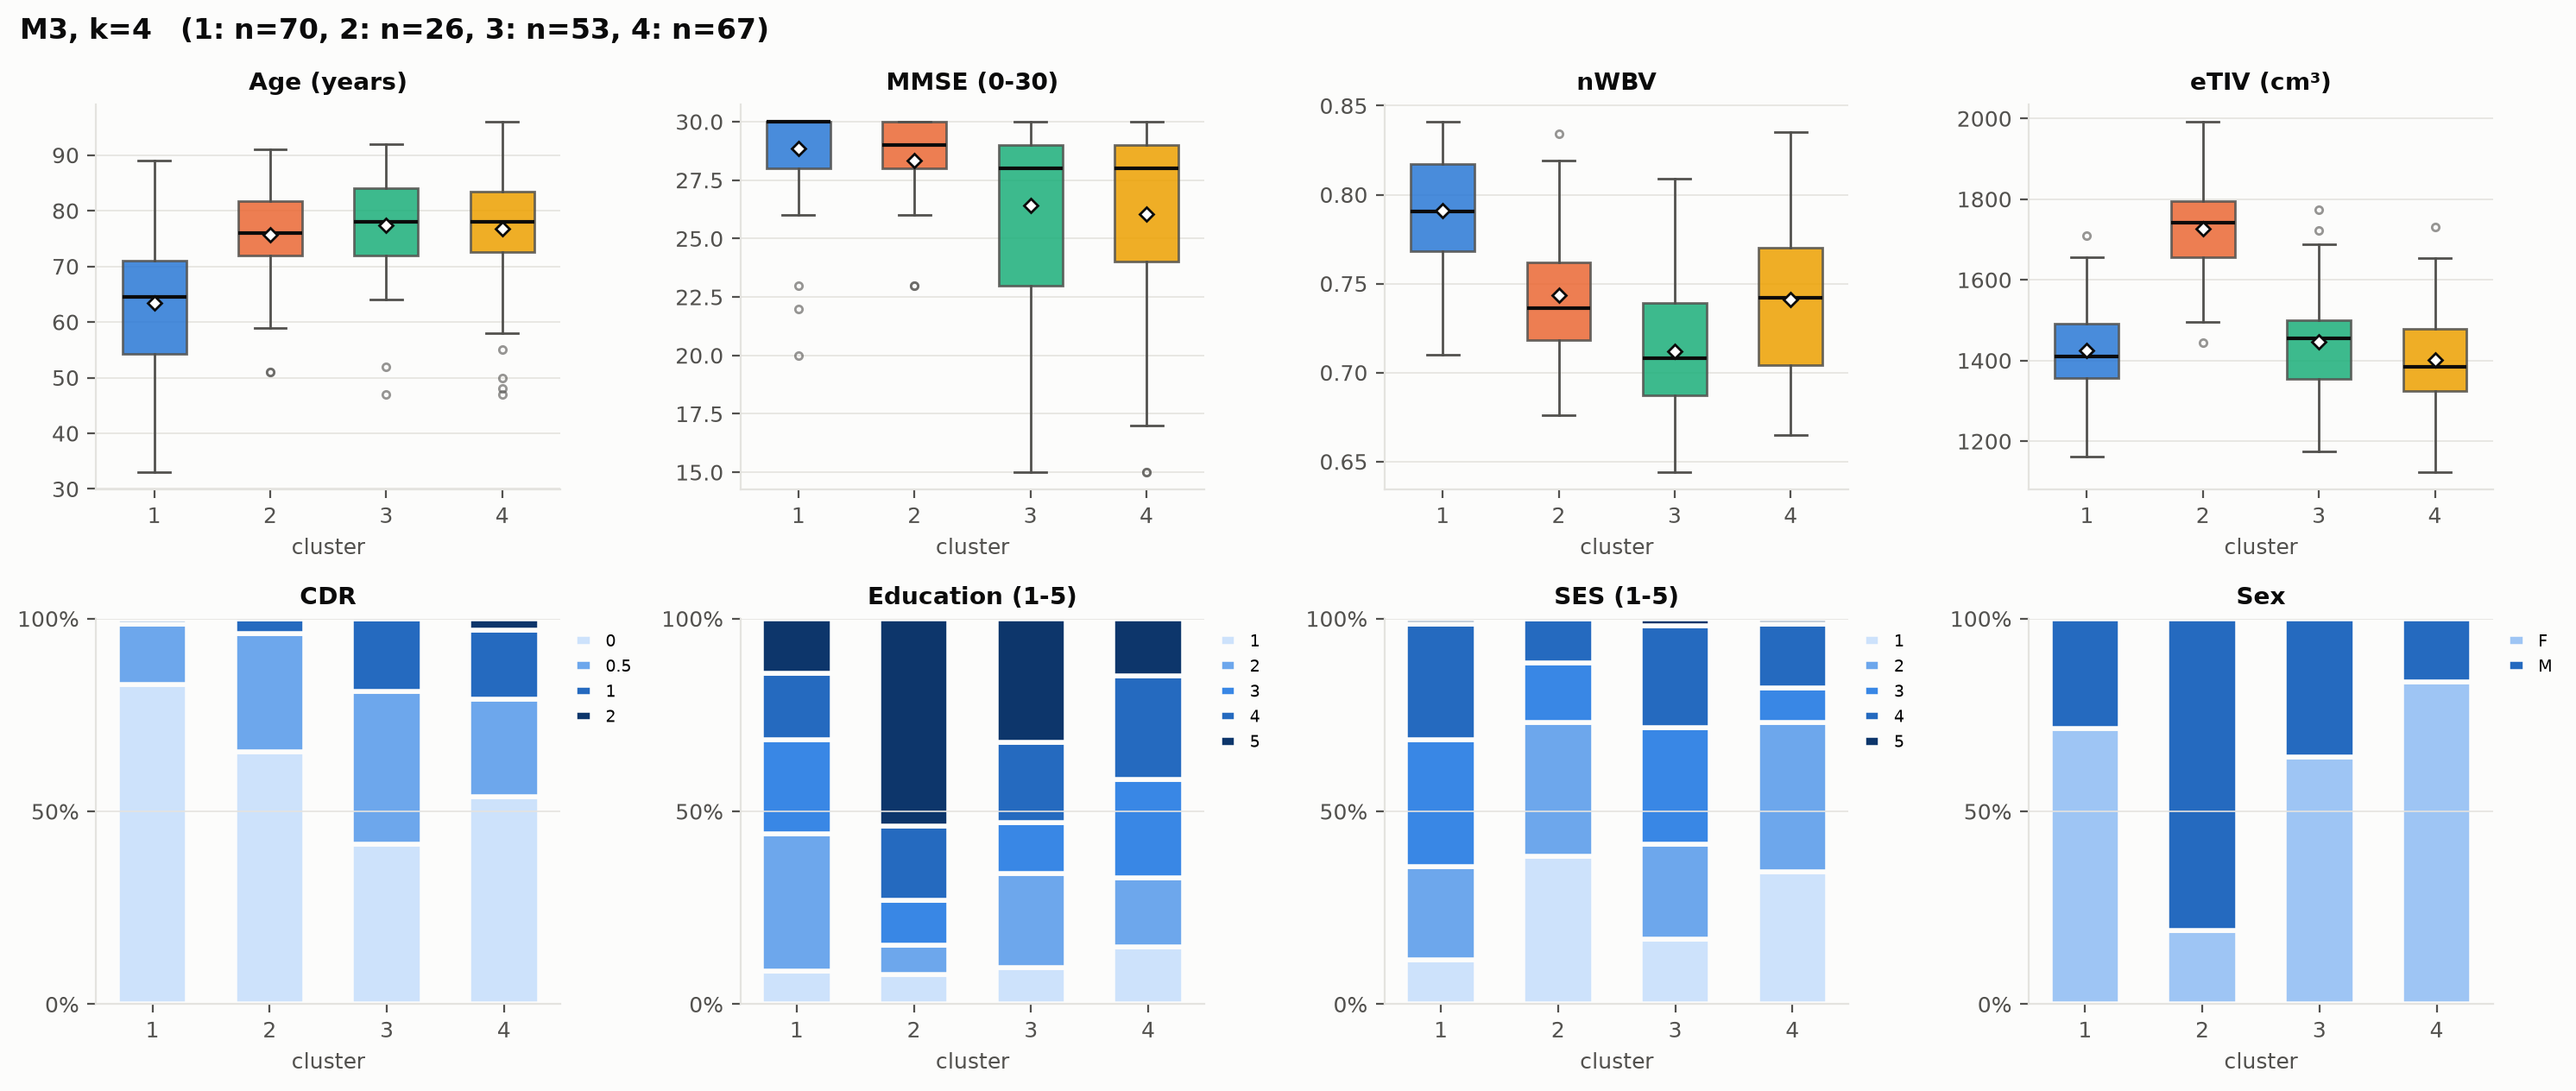

**M2**: Images + clinical, aggregate PSI 0.340

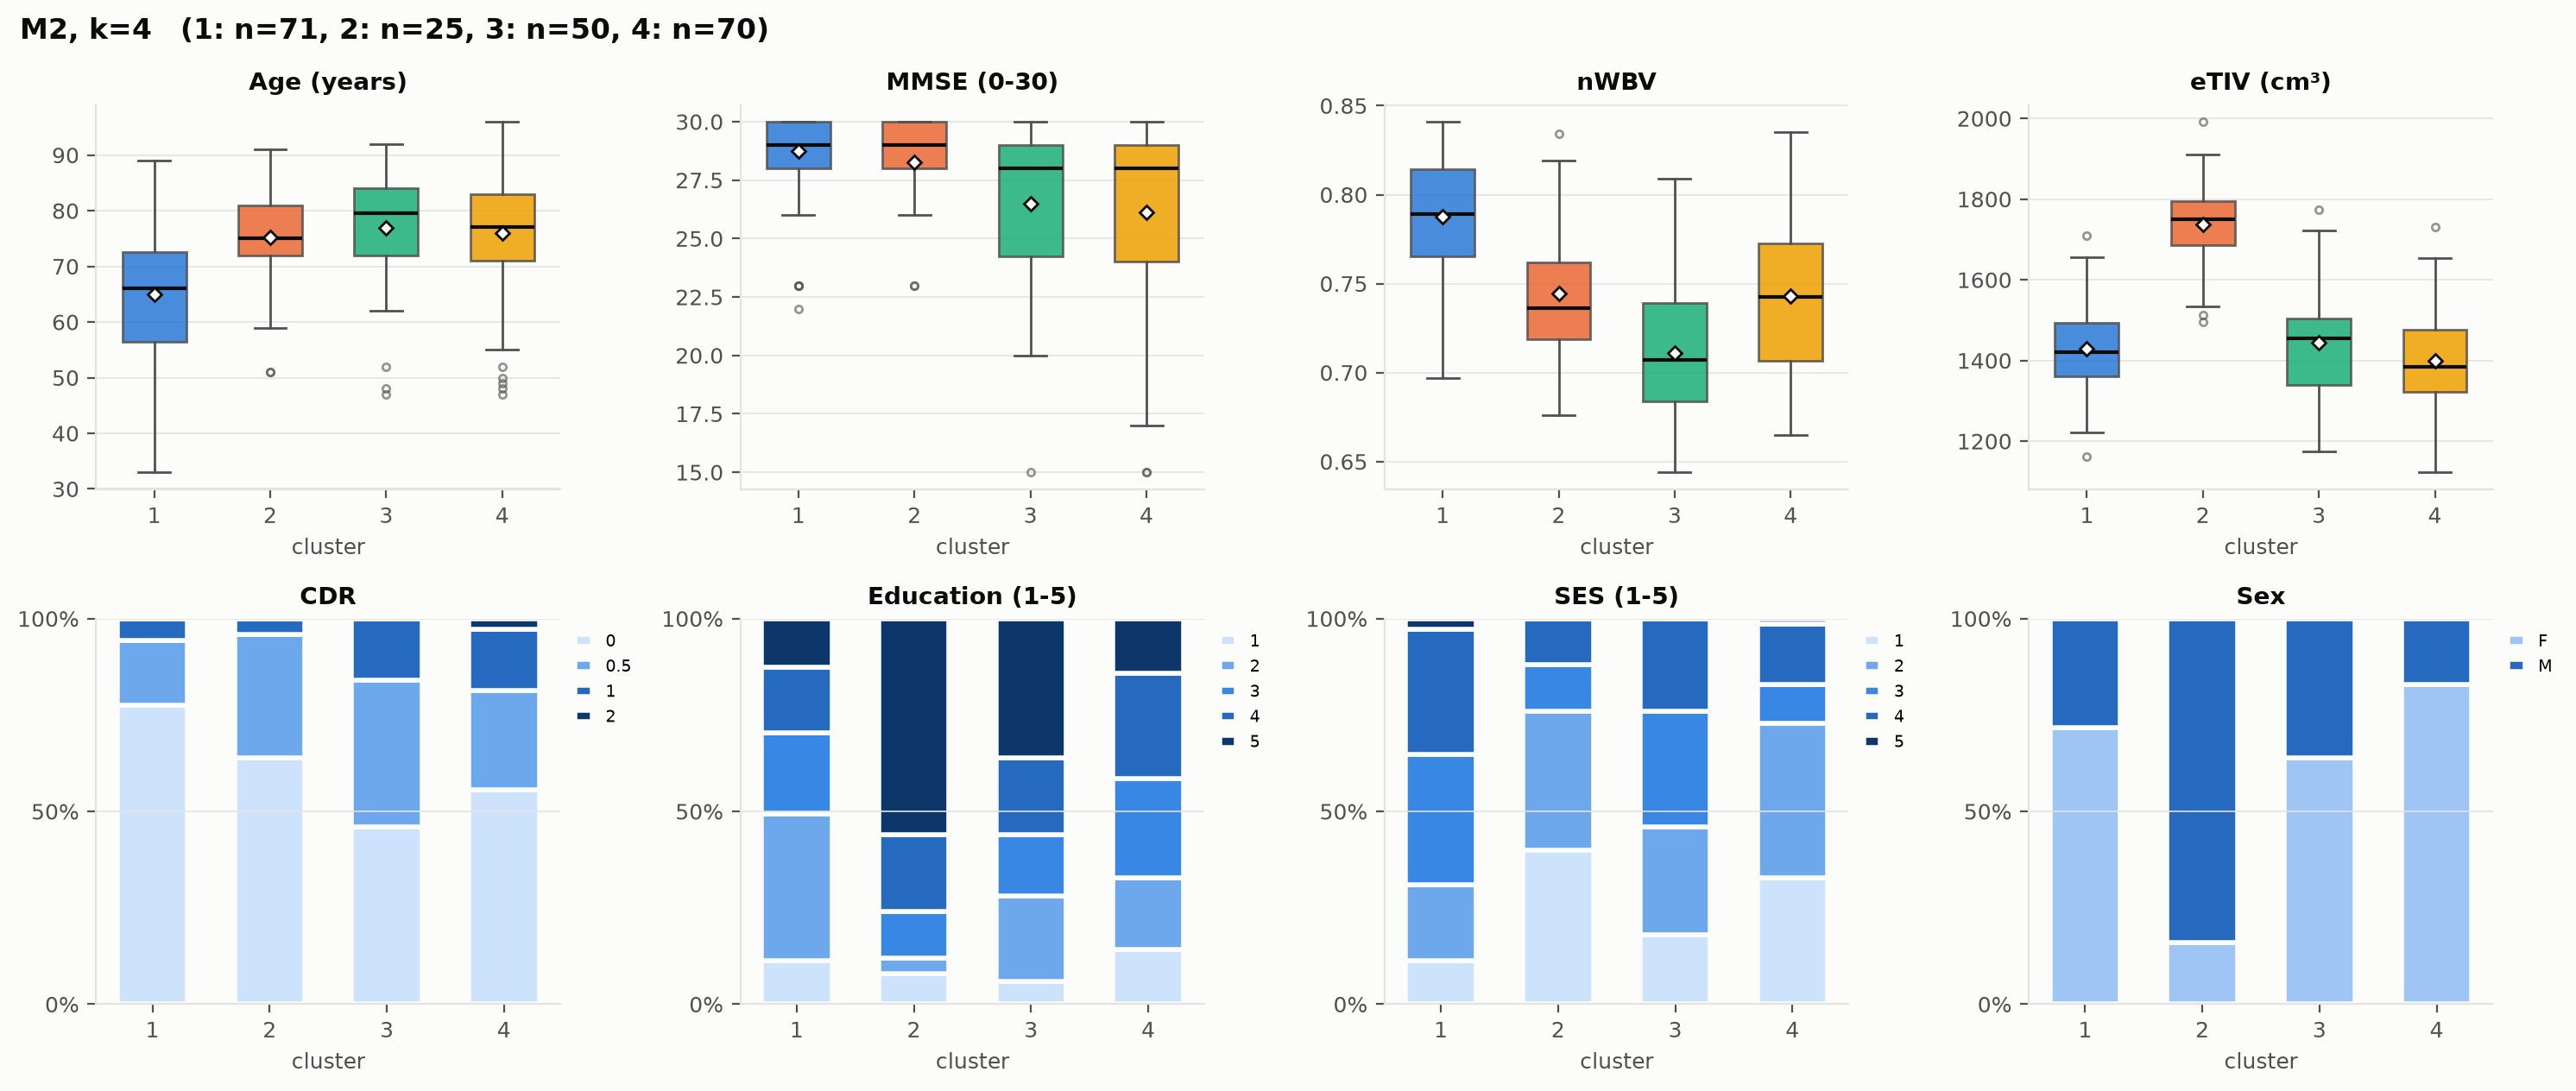

**M1**: Images + clinical, aggregate PSI 0.287

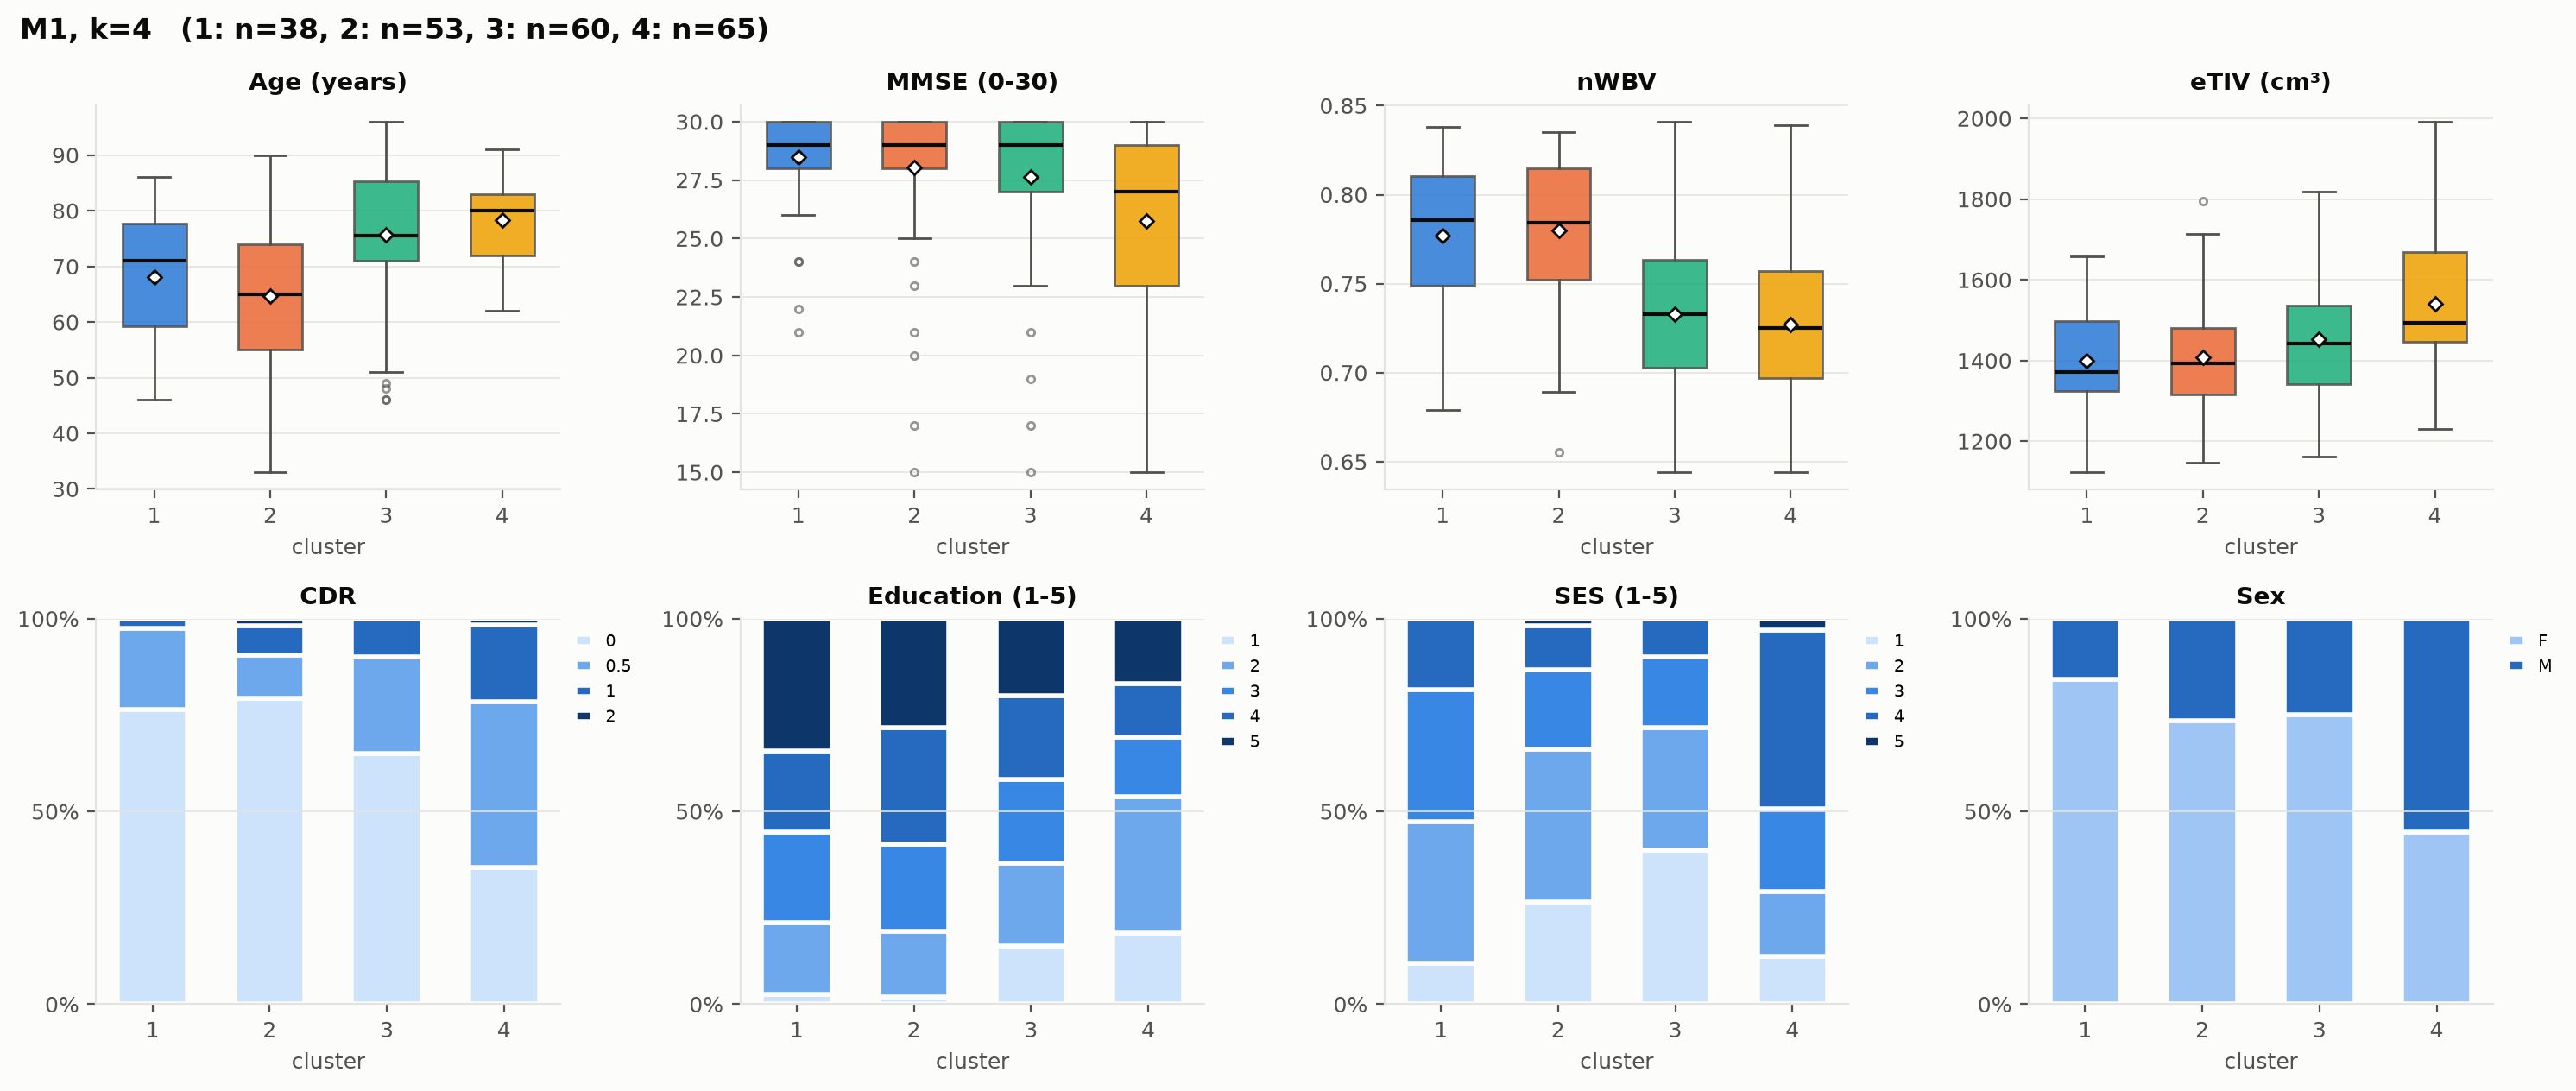

**I2**: Images, aggregate PSI 0.205

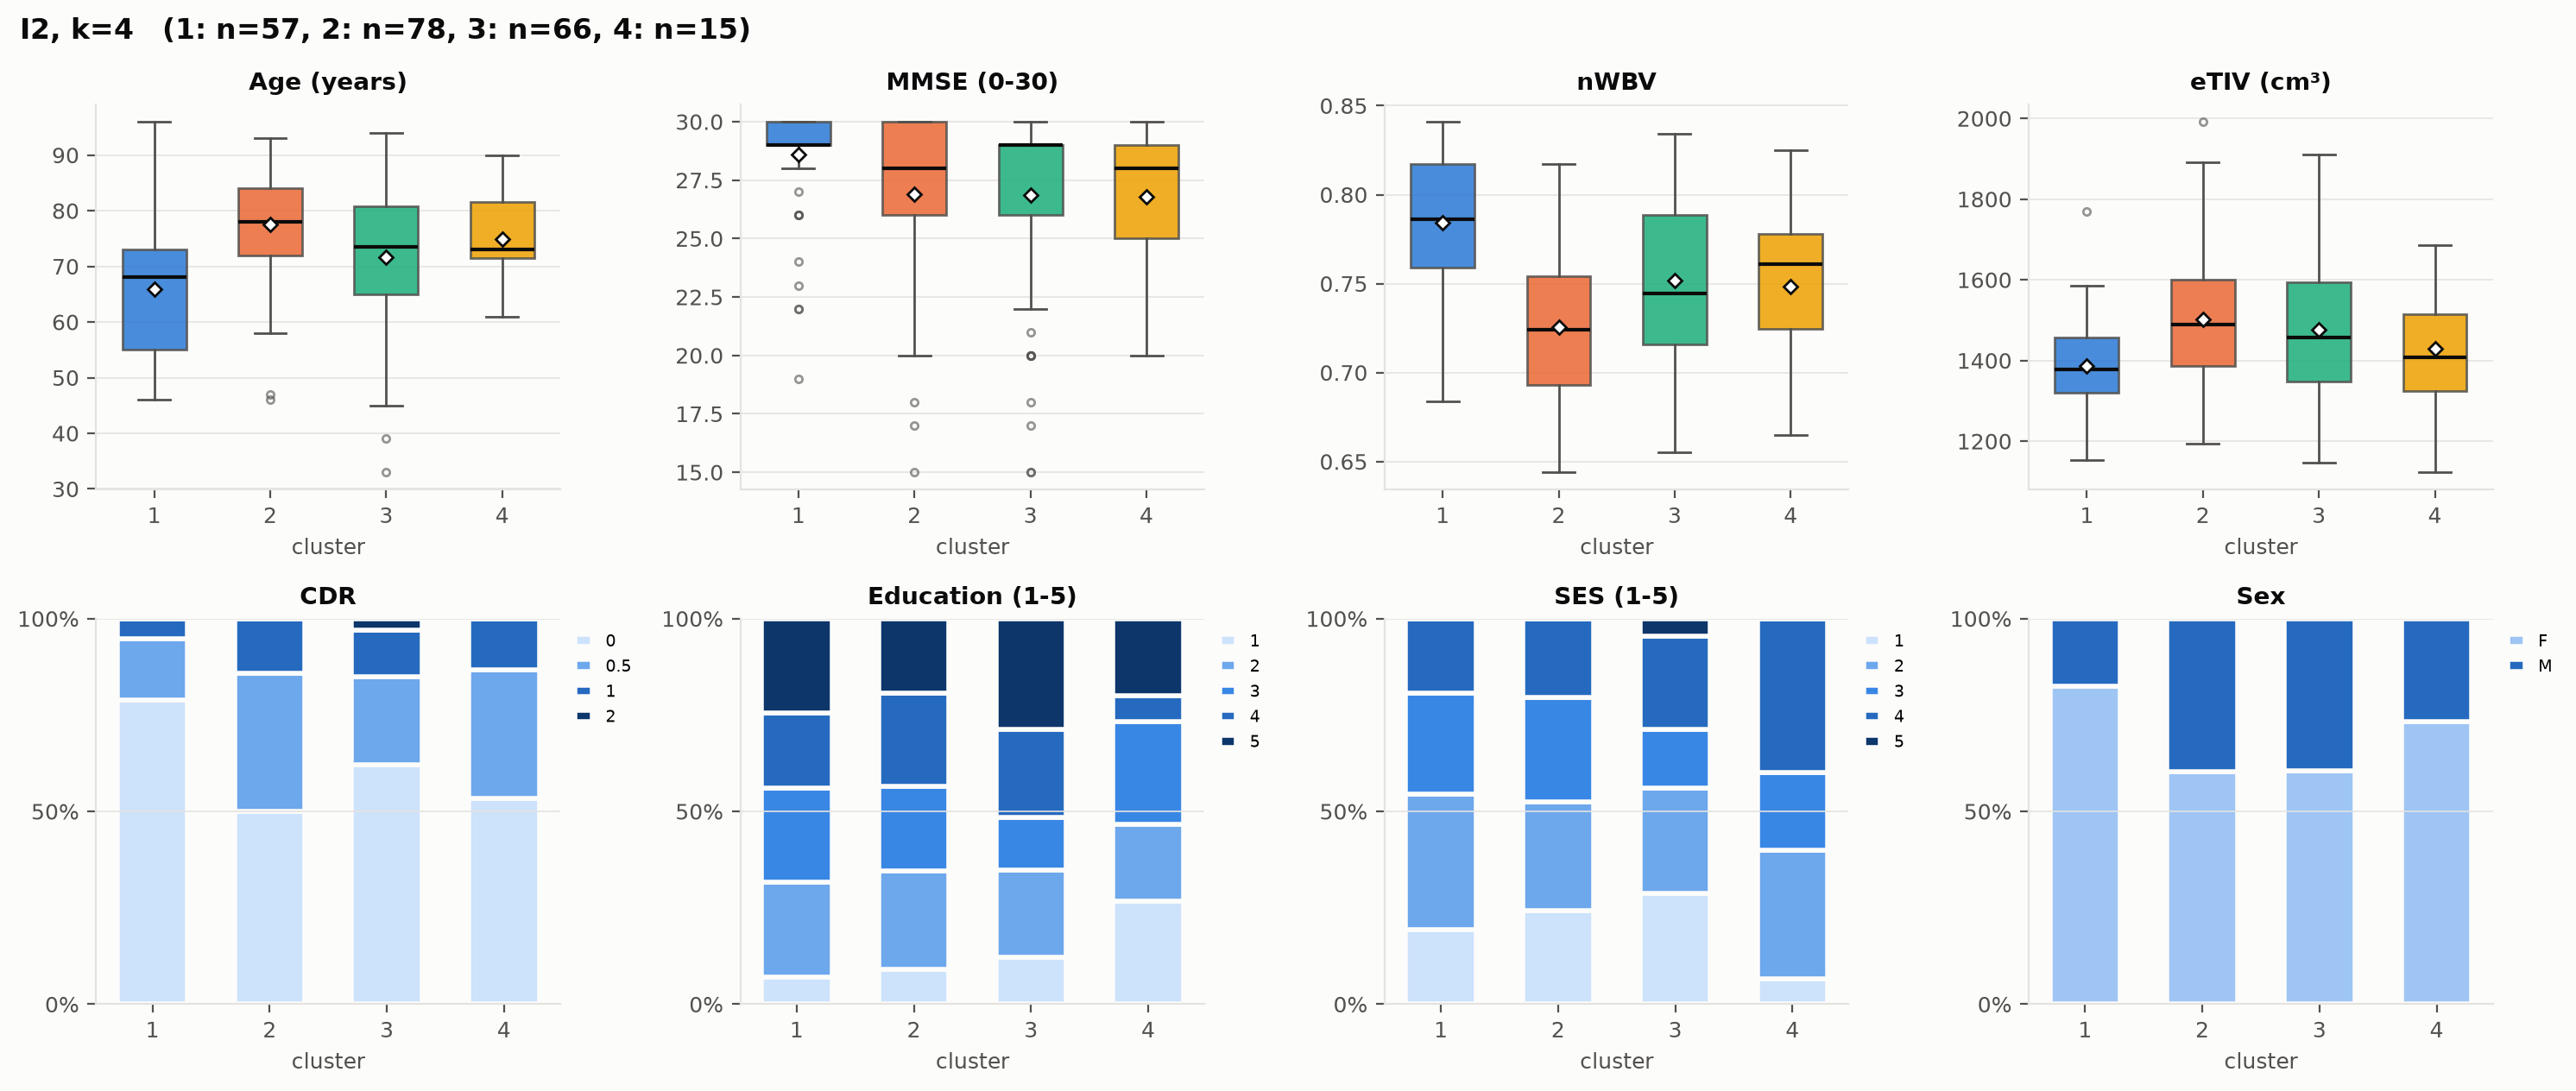

**I1**: Images, aggregate PSI 0.191

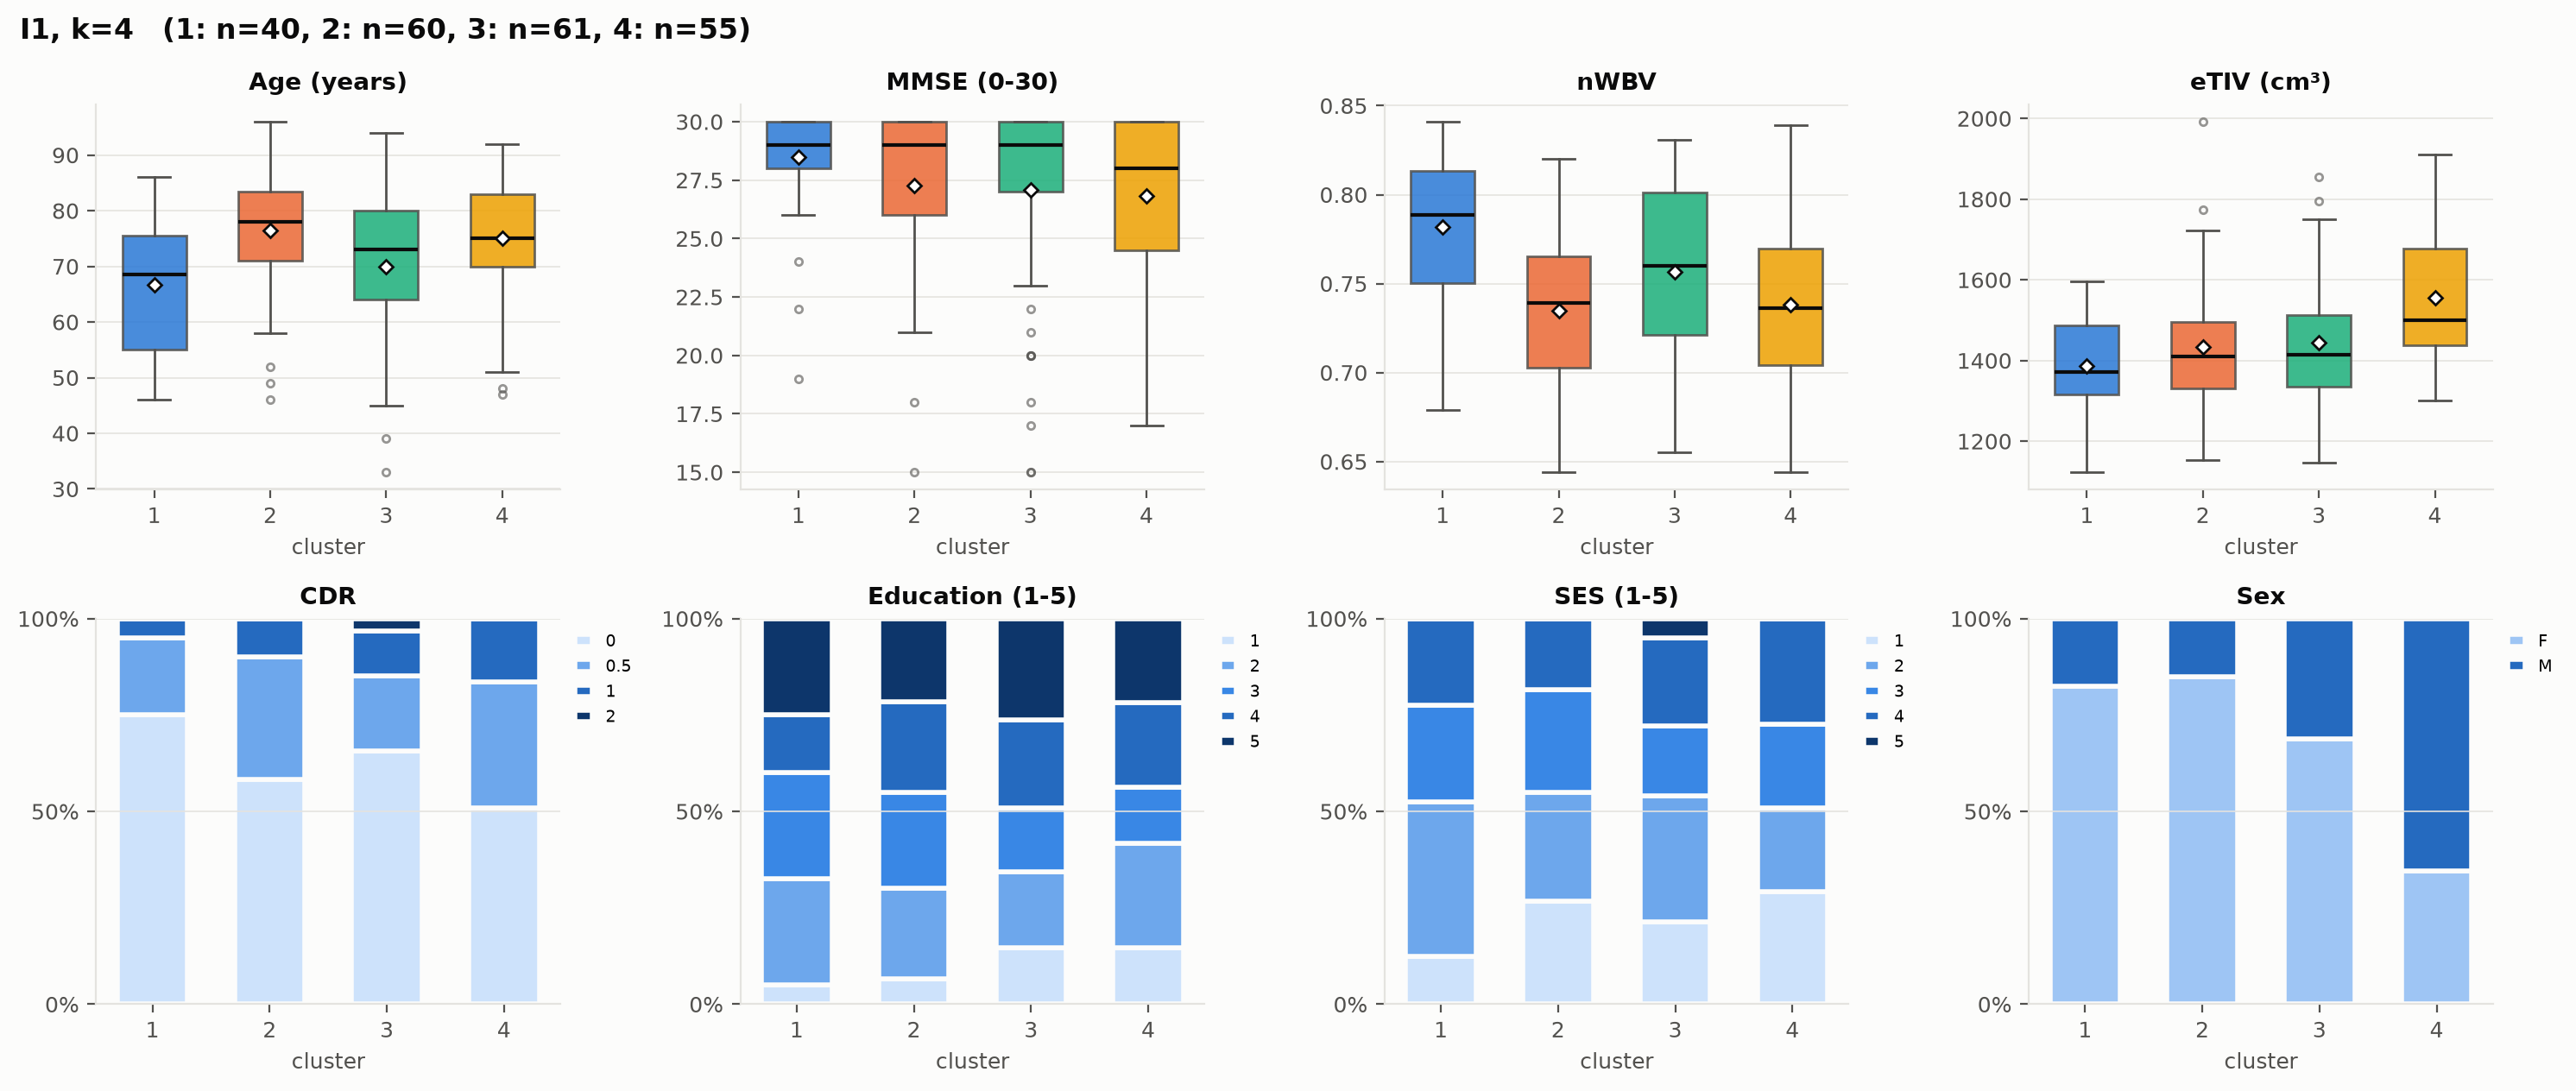

In [7]:
for name in ORDER:
    display(Markdown(f"**{name}**: {cfg.CONFIGS[name]['feature_space']}, aggregate PSI {psi.loc['PSI (mean)', name]:.3f}"))
    show_png(R / "02_compare_configurations" / f"profile_{name}.png")

## 8. Selected configuration

Median [interquartile range] by cluster and the separation of every pair of clusters on every variable.
k-means centroids are not real patients, so each cluster is represented by the patient closest to its centroid.

| Cluster | Label |
|---|---|
| 1 | young, cognitively healthy |
| 2 | older, healthy, lower education |
| 3 | older, highly educated, very mild impairment |
| 4 | cognitively impaired |

,Cluster 1,Cluster 2,Cluster 3,Cluster 4
n (%),47 (22%),72 (33%),67 (31%),30 (14%)
Age,"54 [48, 59]","74 [70, 82]","78 [73, 84]","78 [76, 85]"
MMSE,"30 [29, 30]","29 [28, 30]","28 [26, 30]","21 [19, 23]"
nWBV,"0.814 [0.794, 0.825]","0.764 [0.735, 0.780]","0.730 [0.707, 0.746]","0.693 [0.673, 0.715]"
eTIV (cm³),"1389 [1326, 1516]","1391 [1335, 1478]","1534 [1400, 1662]","1461 [1330, 1495]"
Education (1-5),"4 [3, 5]","2 [2, 3]","5 [4, 5]","2 [1, 2]"
SES (1-5),"2 [1, 2]","3 [3, 4]","1 [1, 2]","4 [3, 4]"
CDR 0 / 0.5 / 1 / 2 (%),100 / 0 / 0 / 0,69 / 29 / 1 / 0,52 / 37 / 10 / 0,3 / 37 / 53 / 7
Men (%),28,26,43,33


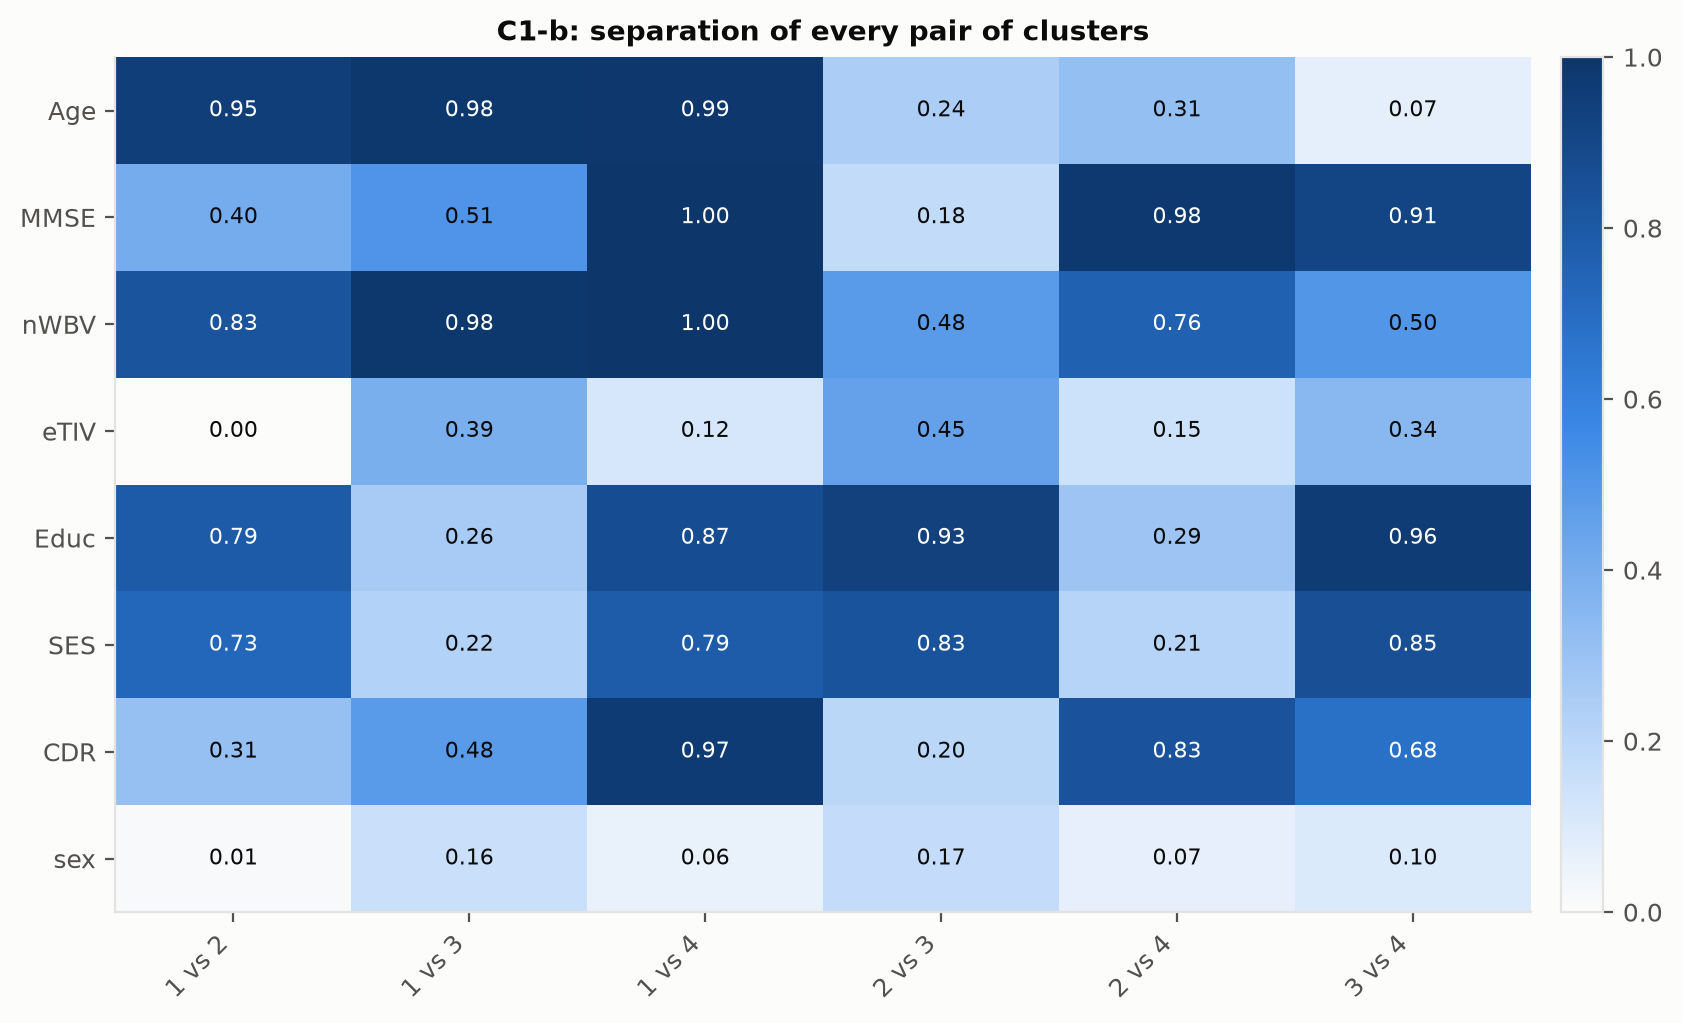

**Representative patients**

,cluster,role,patient,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,representative,OAS1_0345,F,54,30.0,0.0,0.831,1389,4.0,2.0
1,1,neighbour 1,OAS1_0188,M,48,30.0,0.0,0.790,1464,4.0,2.0
2,1,neighbour 2,OAS1_0181,F,49,30.0,0.0,0.820,1316,4.0,2.0
3,2,representative,OAS1_0082,F,75,28.0,0.5,0.776,1407,2.0,3.0
4,2,neighbour 1,OAS1_0001,F,74,29.0,0.0,0.743,1344,2.0,3.0
5,2,neighbour 2,OAS1_0165,F,74,29.0,0.0,0.787,1395,2.0,3.0
6,3,representative,OAS1_0146,F,82,28.0,0.0,0.742,1513,5.0,1.0
7,3,neighbour 1,OAS1_0067,F,71,27.0,1.0,0.730,1549,4.0,1.0
8,3,neighbour 2,OAS1_0180,F,80,30.0,0.0,0.745,1496,4.0,2.0
9,4,representative,OAS1_0134,M,80,20.0,1.0,0.665,1494,2.0,4.0


In [8]:
sel = selection["selected"]
display(pd.read_csv(R / "03_profile_selected" / f"profile_table_{sel}.csv", index_col=0))
show_png(R / "03_profile_selected" / f"pairwise_{sel}.png", 800)
display(Markdown("**Representative patients**"))
display(pd.read_csv(R / "03_profile_selected" / f"representatives_{sel}.csv"))

## 9. Stability

30 bootstrap resamples of the 216 patients; on each, the configuration is refitted and all 216 patients are
assigned to the nearest medoid or centroid. The Adjusted Rand Index is computed between every pair of the 30
partitions (435 pairs). Cross-check: 30 subsamples of 80% without replacement. RelMS configurations are left out
because new patients are assigned with the G-Gower point distance.

,pairs,mean,SD,median,min,max,mean ARI vs full-data partition,80% subsamples (mean)
configuration,,,,,,,,
C1-b,435,0.762,0.115,0.784,0.345,0.950,0.827,0.873
C1,435,0.272,0.130,0.247,0.047,0.764,0.369,0.448
C2,435,0.234,0.124,0.211,0.029,0.832,0.348,0.387
I2,435,0.155,0.096,0.146,-0.045,0.681,0.204,0.408
M2,435,0.108,0.080,0.094,-0.024,0.531,0.127,0.276
M3,435,0.100,0.073,0.085,-0.043,0.449,0.128,0.266


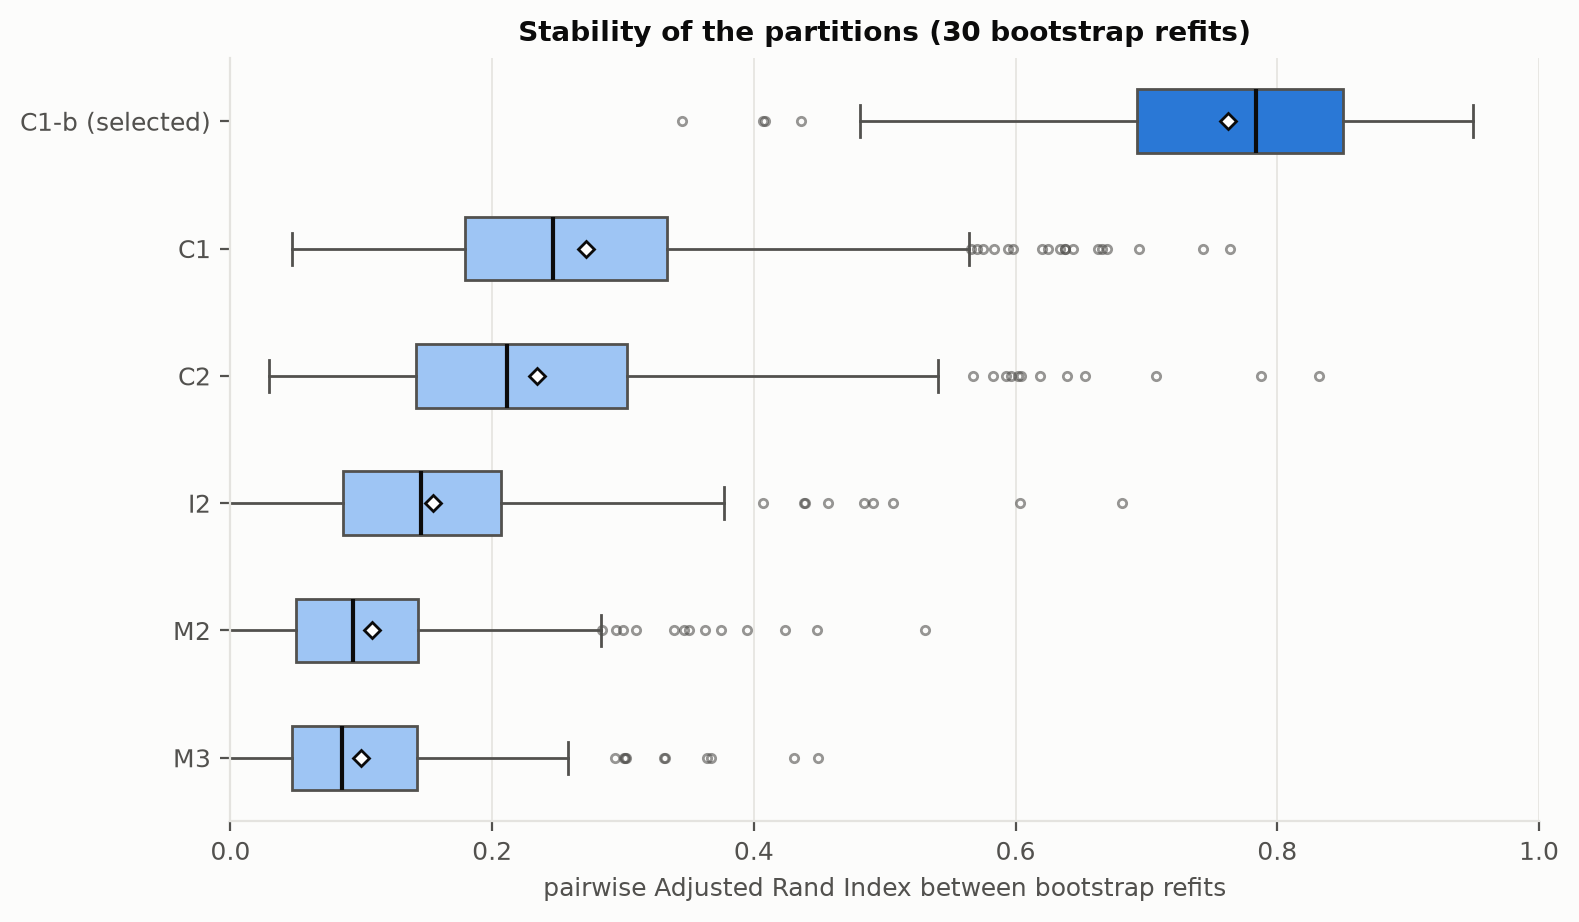

In [9]:
st = pd.read_csv(R / "04_stability" / "stability_summary.csv", index_col=0)
sub = pd.read_csv(R / "04_stability" / "stability_subsampling80.csv", index_col=0)
st["80% subsamples (mean)"] = sub["mean"]
display(st.round(3))
show_png(R / "04_stability" / "stability_boxplot.png", 750)

## 10. Robustness checks and secondary results

Number of image components: PCA refitted on the 216 patients for τ = 0.50, 0.592 and 0.90, and every image
configuration refitted. Aggregate PSI:

In [10]:
t = pd.read_csv(R / "06_pca_robustness" / "aggregate_psi_by_tau.csv", index_col=0)
t.columns = ["main (416 patients, 110 PCs)", "τ = 0.50 (55 PCs)", "τ = 0.592 (72 PCs)", "τ = 0.90 (163 PCs)"]
display(t.round(3))

,"main (416 patients, 110 PCs)",τ = 0.50 (55 PCs),τ = 0.592 (72 PCs),τ = 0.90 (163 PCs)
C1,0.440,0.440,0.440,0.440
C1-b,0.527,0.527,0.527,0.527
C2,0.419,0.419,0.419,0.419
I1,0.191,0.188,0.196,0.192
I2,0.205,0.229,0.209,0.219
M1,0.287,0.267,0.267,0.347
M2,0.340,0.293,0.286,0.431
M3,0.345,0.290,0.299,0.430


Number of clusters: aggregate PSI of every configuration for k = 2 to 5:

In [11]:
path = OUT / "psi_all_configurations_by_k.csv"
if not path.exists():
    rows = {}
    for name in cfg.CONFIGS:
        for k in cfg.K_CANDIDATES:
            r = fit_configuration(name, k, df, metric=selection["m3_metric"] if name == "M3" else None)
            rows[(name, f"k = {k}")] = psi_column(df, r["labels"], name)["PSI (mean)"]
    pd.Series(rows).unstack().to_csv(path)
display(pd.read_csv(path, index_col=0).loc[ORDER].round(3))

,k = 2,k = 3,k = 4,k = 5
C1-b,0.441,0.494,0.527,0.529
C1,0.225,0.380,0.440,0.444
C2,0.232,0.328,0.419,0.394
M3,0.249,0.339,0.345,0.358
M2,0.307,0.352,0.340,0.400
M1,0.217,0.256,0.287,0.340
I2,0.269,0.206,0.205,0.256
I1,0.073,0.182,0.191,0.179


Silhouette width in each configuration's own distance (comparable only within a distance family), and agreement with CDR (merged into 0 / 0.5 / ≥ 1 and healthy / impaired; C2 and M3 use CDR as an input):

In [12]:
display(pd.read_csv(R / "05_secondary_results" / "silhouette_by_family.csv", index_col=[0, 1]))
display(pd.read_csv(R / "05_secondary_results" / "agreement_with_cdr.csv", index_col=0).round(3))

feature space  silhouette
distance family     configuration                                     
Euclidean (k-means) C1-b                          Clinical       0.257
RelMS               I1                              Images       0.020
                    M1                   Images + clinical       0.022
Robust G-Gower      C1                            Clinical       0.140
                    C2                      Clinical + CDR       0.112
                    I2                              Images       0.023
                    M2                   Images + clinical       0.021
                    M3             Images + clinical + CDR       0.020

,CDR is an input,ARI (0 / 0.5 / ≥1),NMI (0 / 0.5 / ≥1),ARI (healthy / impaired),NMI (healthy / impaired)
configuration,,,,,
C1,no,0.093,0.184,0.126,0.189
C1-b,no,0.133,0.249,0.124,0.226
C2,yes,0.177,0.340,0.205,0.316
I1,no,-0.002,0.018,0.003,0.015
I2,no,0.010,0.030,0.019,0.030
M1,no,0.030,0.067,0.052,0.068
M2,no,0.030,0.038,0.034,0.033
M3,yes,0.053,0.070,0.061,0.060


## 11. Comparison with the previous method

The previous method (RelMS on the five image blocks plus an unscaled Euclidean clinical block with ASF; sex,
Education and SES as Hamming), refitted at k = 4 on the same 216 patients, against the selected configuration.

,Age,MMSE,nWBV,eTIV,Educ,SES,CDR,sex,PSI (mean)
previous method,0.033,0.064,0.128,0.652,0.474,0.498,0.096,0.354,0.287
selected (C1-b),0.592,0.662,0.760,0.241,0.683,0.606,0.577,0.094,0.527


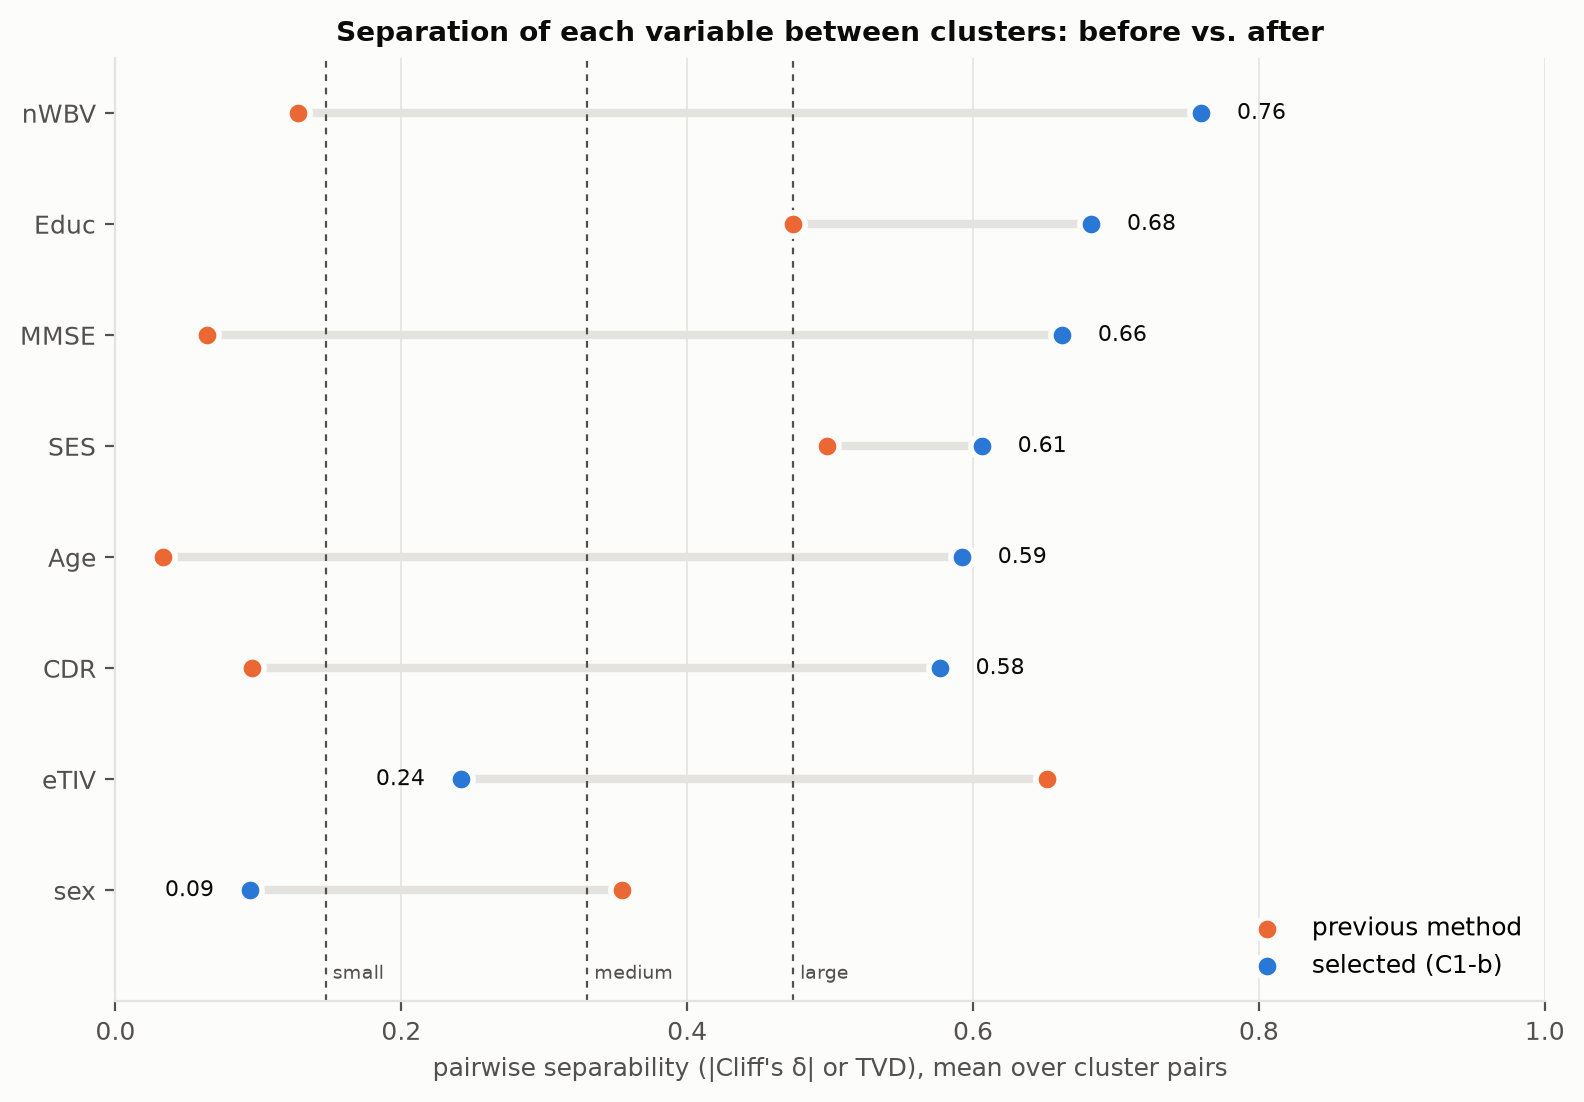

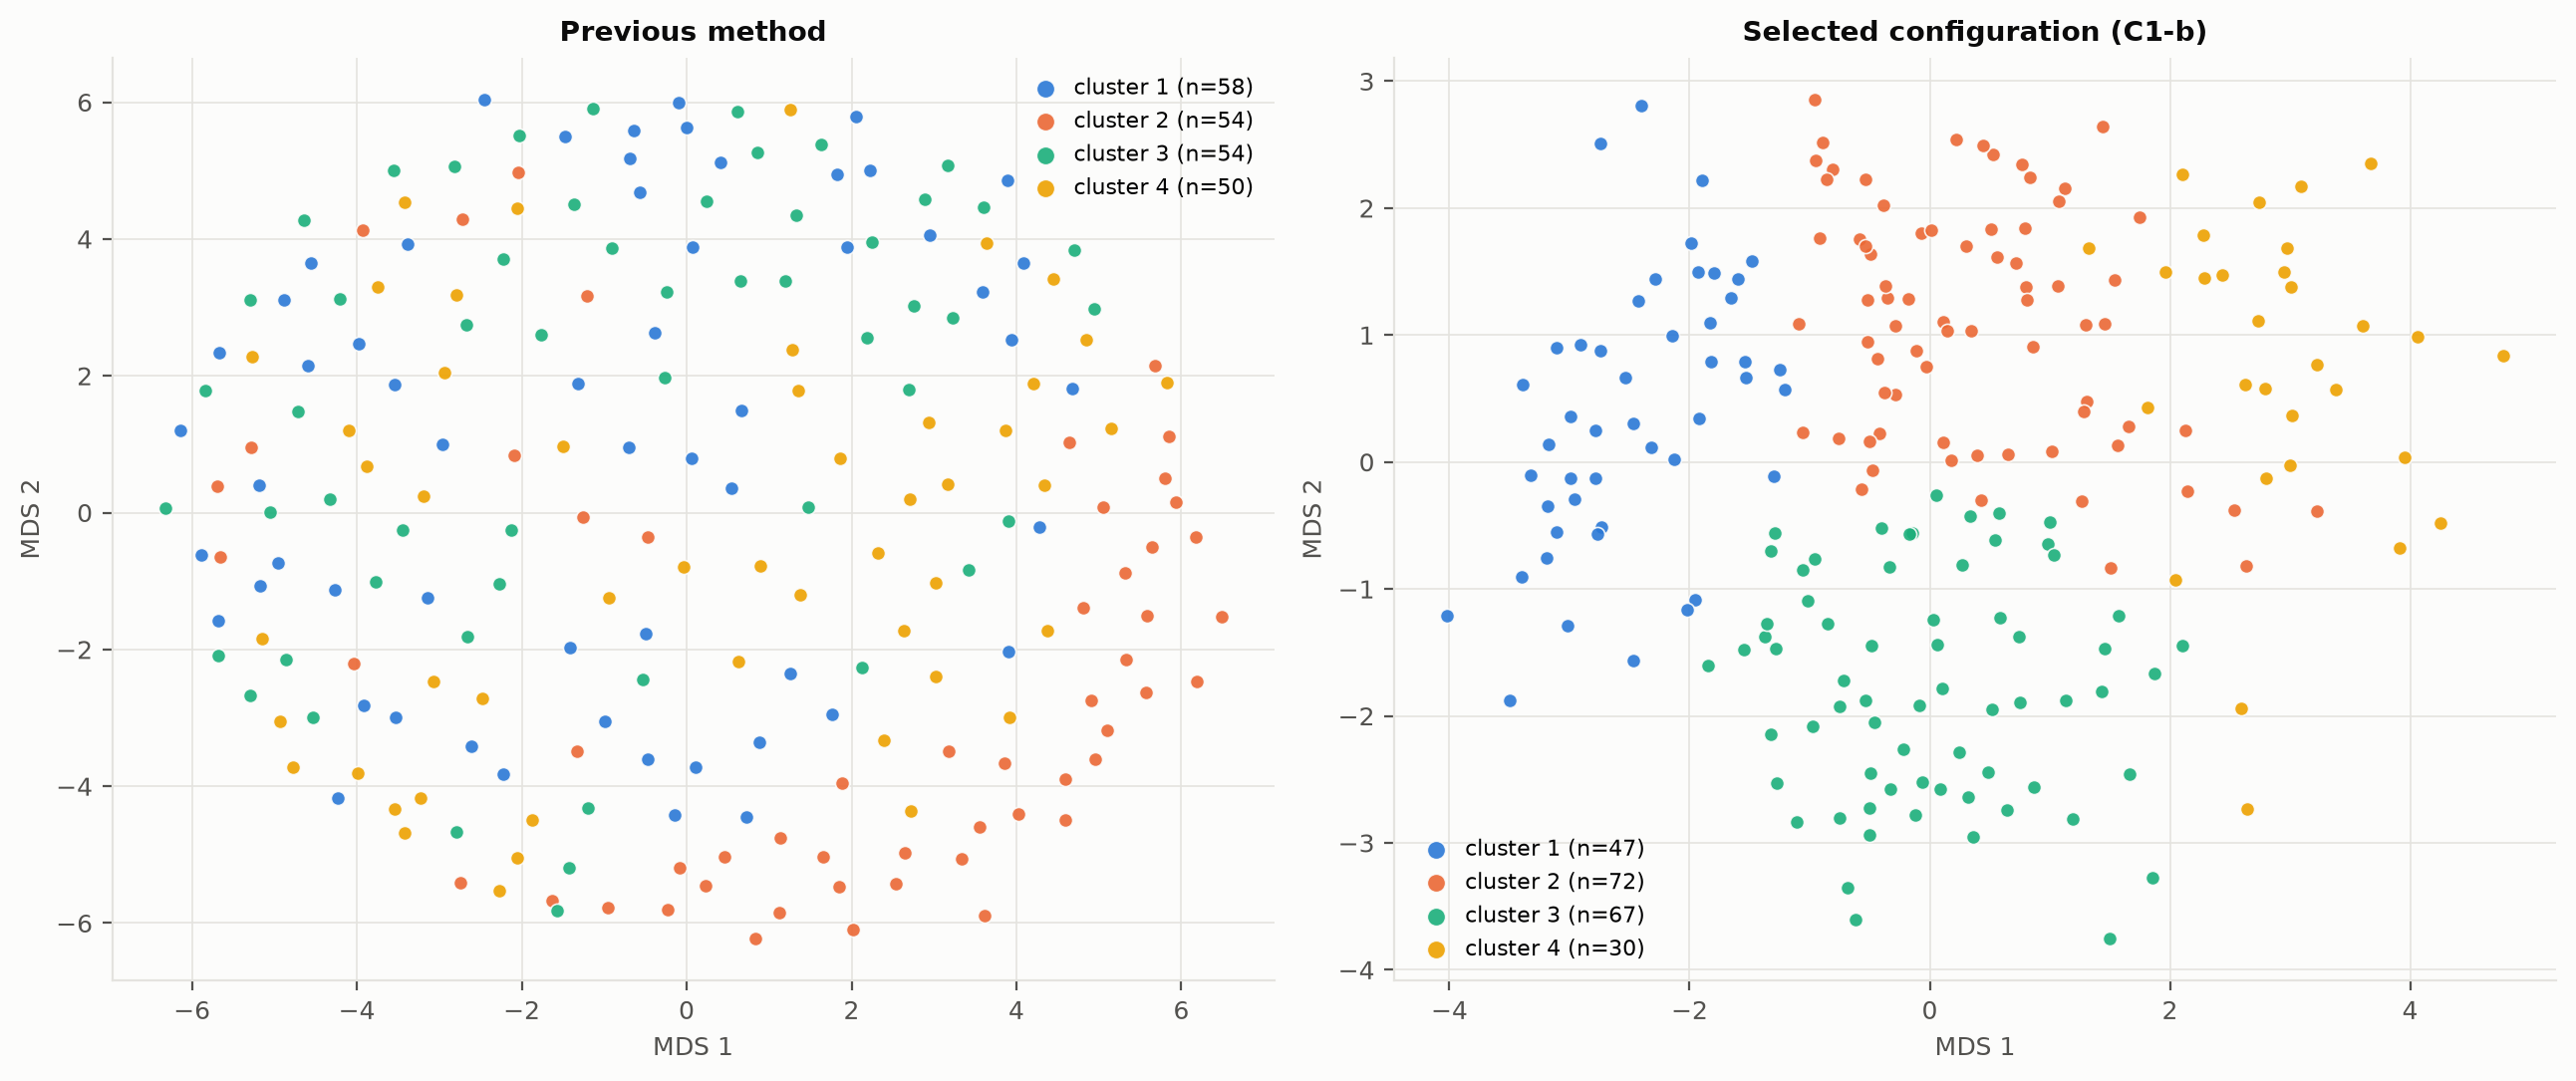

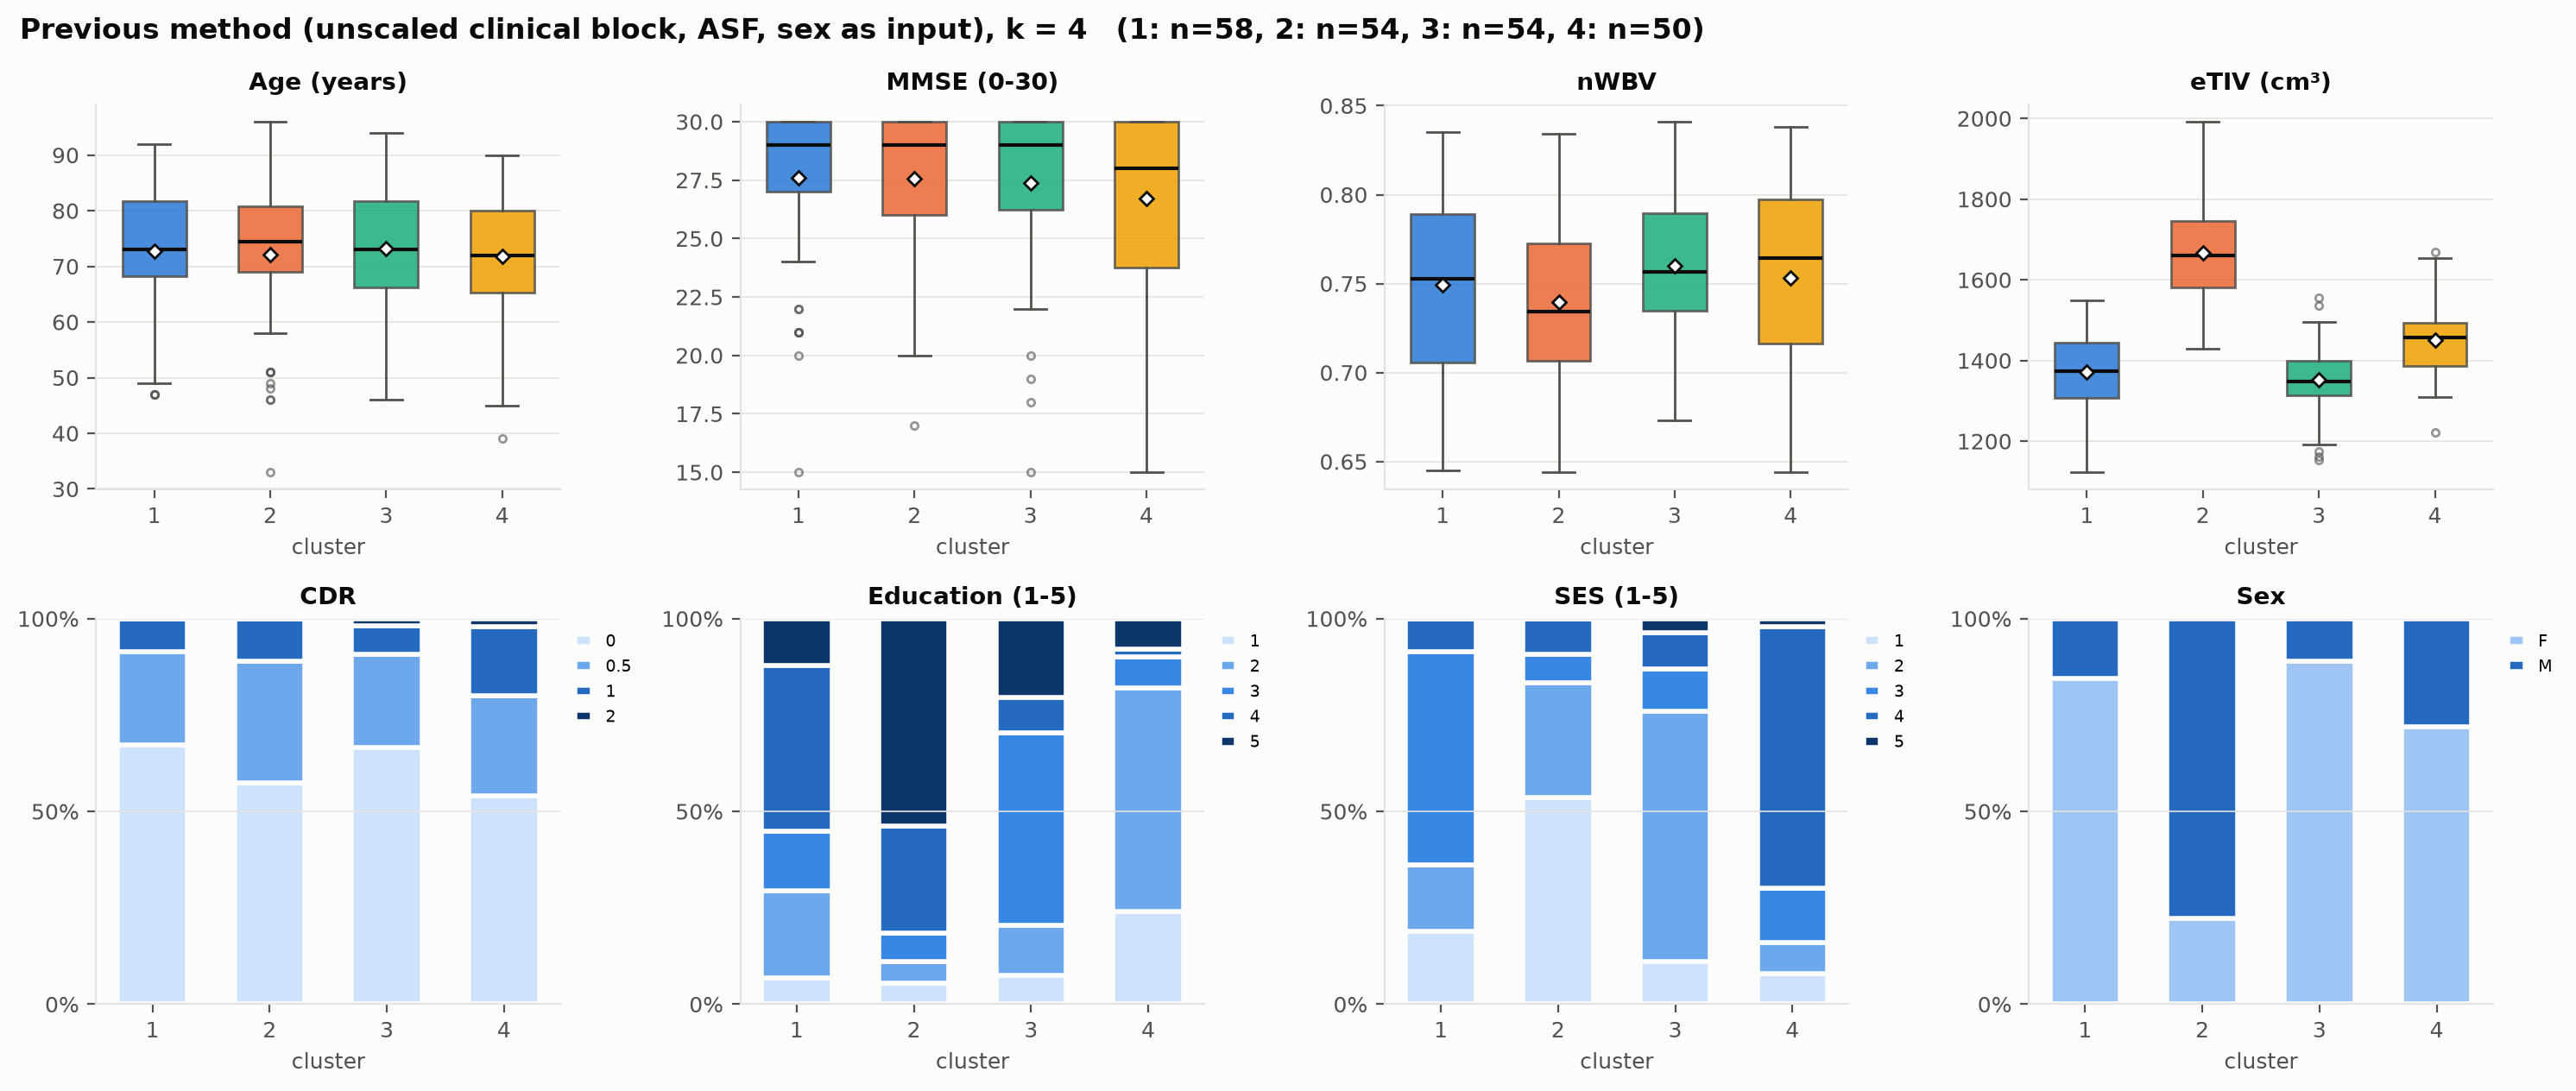

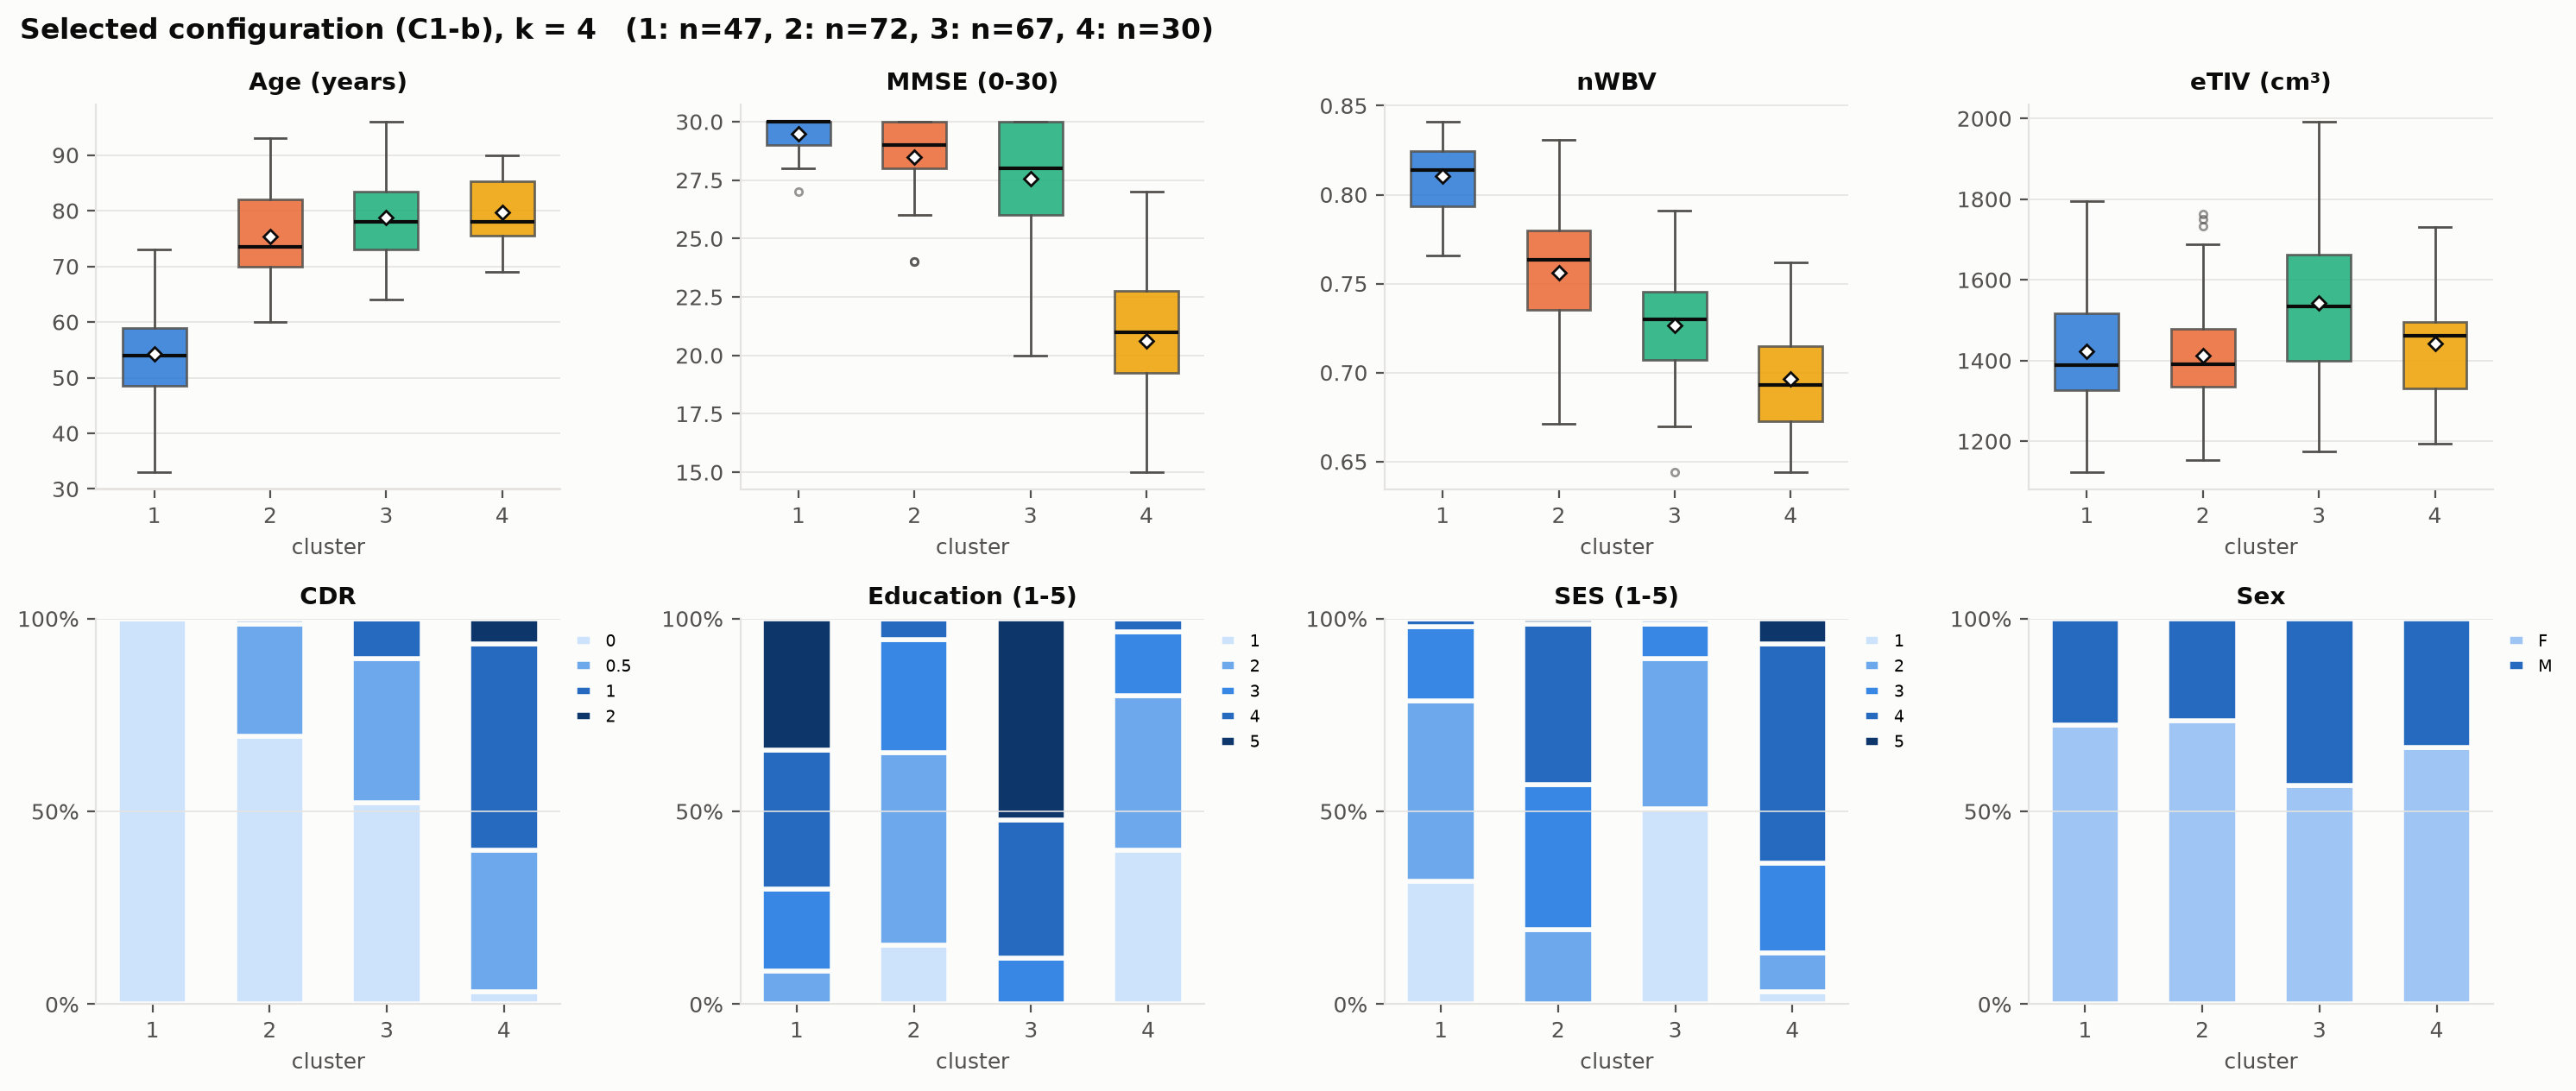

In [13]:
display(pd.read_csv(R / "07_before_after" / "psi_before_after.csv", index_col=0).T.round(3))
show_png(R / "07_before_after" / "psi_before_after.png", 750)
show_png(R / "07_before_after" / "mds_before_after.png")
show_png(R / "07_before_after" / "profile_before.png")
show_png(R / "07_before_after" / "profile_after.png")